# Milestone 2: Conditional Generation and Tuning

**Generative Project (Text to Image) · IE 7615**

This notebook connects a text encoder to Stable Diffusion v1.5, runs a baseline, tunes
classifier-free guidance and the noise schedule, and records the generated images. Two additions go
beyond the core brief: **BERT** is connected to the same diffusion model through a small adapter we
train, and the tuned settings are confirmed on a **held-out prompt set** that played no part in
choosing them.

| Section | Milestone task |
|---|---|
| 4. Integration | Integrate the text encoder (CLIP) with the diffusion model |
| 6. Baseline | Run baseline conditional generation |
| 7. Guidance sweep | Tune classifier-free guidance (7 settings) |
| 8. Noise schedule | Tune the noise schedule: sampler (6), beta schedule (3), timestep spacing (3), step count (5) |
| 9. DDPM | The original DDPM sampler at 1,000 steps, against a fast solver |
| 10. BERT | Integrate BERT with the same diffusion model: raw, then through a trained adapter (training log) |
| 11. Held-out check | Tuned settings against the baseline on 10 unseen prompts |
| 12–13. Results and logs | First set of generated images, results table, generation log |

**How the comparison stays fair.** Every configuration renders the same prompts from the same
starting latents, drawn once on a CPU generator. A change in the result therefore comes from the
setting under test, not from a different random start. Because the same prompts run under every
setting, each configuration is compared with the baseline **prompt by prompt** (a paired
difference, with its standard error), which is far more sensitive than comparing two averages.

**Metrics.** Both come from CLIP ViT-L/14, the same scorer as Milestone 1:

* **CLIP score**: 100 × cosine(prompt, generated image). How closely the image follows its prompt.
* **Real-image similarity**: cosine(generated image, the real COCO photo for that caption). How close
  the image lands to the scene the caption was written for.

## 1. Setup

In [1]:
# Kaggle ships PyTorch and transformers; this adds diffusers
!pip install -q "diffusers>=0.31" ftfy

In [2]:
import json
import math
import textwrap
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image

import diffusers
import transformers
from diffusers import (
    DDIMScheduler,
    DDPMScheduler,
    DPMSolverMultistepScheduler,
    EulerAncestralDiscreteScheduler,
    EulerDiscreteScheduler,
    PNDMScheduler,
    StableDiffusionPipeline,
)
from transformers import AutoModel, AutoTokenizer, CLIPModel, CLIPProcessor

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="torch.nn.modules.transformer")
transformers.logging.set_verbosity_error()
diffusers.logging.set_verbosity_error()
%config InlineBackend.figure_formats = ["jpeg"]

# ---------------- Config ----------------
SEED = 42

# Models (CLIP and SD as in Milestone 1)
SD_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CLIP_MODEL_ID = "openai/clip-vit-large-patch14"  # SD v1.5's text encoder, also our scorer
BERT_MODEL_ID = "google-bert/bert-base-uncased"  # the comparison encoder from Milestone 1

# Prompt sets: one to tune on, one held out to confirm the result
N_PROMPTS = 10
PROMPT_WORDS = (8, 18)  # long enough to describe a scene, short enough to stay literal
BLOCKLIST = {"sexy", "naked", "nude", "bikini", "underwear", "lingerie", "shirtless"}

# Generation
IMAGE_SIZE = 512
BATCH = 5  # images per pipeline call; 5 at 512 px stays well inside a 16 GB T4

# Baseline: the pipeline's own defaults for SD v1.5
BASE = dict(sampler="pndm", steps=50, cfg=7.5)

# Guidance sweep
CFG_VALUES = [1.0, 3.0, 5.0, 7.5, 10.0, 15.0]
RESCALE_AT_HIGH_CFG = 0.7  # guidance_rescale, tried once at the highest scale

# Noise-schedule sweeps (the brief asks for at least 3 values each)
SAMPLERS = ["pndm", "ddim", "euler", "euler_a", "dpmpp_2m", "ddpm"]
SAMPLER_STEPS = 30  # equal step budget, so the sampler is the only thing that changes
SCHEDULE_SAMPLER, SCHEDULE_STEPS = "ddim", 30  # used for the beta and spacing sweeps
BETA_SCHEDULES = ["scaled_linear", "linear", "squaredcos_cap_v2"]
TIMESTEP_SPACINGS = ["leading", "linspace", "trailing"]
STEPS_SAMPLER = "dpmpp_2m"
STEP_COUNTS = [10, 20, 30, 50]
KARRAS_STEPS = 10  # Karras sigmas matter most at low step counts
DDPM_FULL_STEPS, DDPM_N_PROMPTS = 1000, 2

# BERT -> CLIP adapter (section 10)
ADAPTER = dict(layers=3, heads=8, ff=2048, dropout=0.1)
TRAIN = dict(epochs=30, batch=64, lr=3e-4, weight_decay=0.01, warmup_frac=0.05, val_frac=0.05, n_empty=64)

# Paths
KAGGLE = Path("/kaggle/working").is_dir()
OUT_DIR = Path("/kaggle/working/outputs/milestone2" if KAGGLE else "outputs/milestone2")

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
assert DEVICE == "cuda", "This notebook needs a GPU (Kaggle: Settings -> Accelerator -> GPU T4)"

torch.manual_seed(SEED)
np.random.seed(SEED)

IMAGES_DIR, GRIDS_DIR, TABLES_DIR = OUT_DIR / "images", OUT_DIR / "grids", OUT_DIR / "tables"
for d in (IMAGES_DIR, GRIDS_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

gpu = torch.cuda.get_device_properties(0)
print(f"torch {torch.__version__} | diffusers {diffusers.__version__} | transformers {transformers.__version__}")
print(f"device: {gpu.name}, {gpu.total_memory / 1024**3:.1f} GB")
print(f"outputs: {OUT_DIR}")

torch 2.11.0+cu130 | diffusers 0.42.0 | transformers 5.20.2
device: Tesla T4, 14.6 GB
outputs: /kaggle/working/outputs/milestone2


## 2. Models

One CLIP ViT-L/14 checkpoint plays two roles. Its **text tower** is our text encoder: it turns each
prompt into the 77 × 768 token embeddings that the UNet cross-attends to. Its **joint text–image
space** is the scorer. Stable Diffusion's own copy of the text encoder is never called during
generation.

In [4]:
pipe = StableDiffusionPipeline.from_pretrained(
    SD_MODEL_ID, torch_dtype=DTYPE, variant="fp16", use_safetensors=True
).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
pipe.vae.enable_slicing()  # decode one image at a time, keeps the VAE's memory peak low

# Every scheduler below is built from this config, so SD v1.5's trained noise settings carry over
BASE_SCHEDULER_CONFIG = dict(pipe.scheduler.config)

clip_model = CLIPModel.from_pretrained(CLIP_MODEL_ID, torch_dtype=DTYPE).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
tokenizer = clip_processor.tokenizer
SEQ_LEN = tokenizer.model_max_length  # 77


def n_params(module):
    return f"{sum(p.numel() for p in module.parameters()) / 1e6:.0f}M"


display(pd.DataFrame(
    [
        ("Text encoder (ours)", "CLIP ViT-L/14 text tower", n_params(clip_model.text_model), "prompt -> 77 x 768"),
        ("UNet", type(pipe.unet).__name__, n_params(pipe.unet), "4 x 64 x 64 latent, cross-attends to 77 x 768"),
        ("VAE", type(pipe.vae).__name__, n_params(pipe.vae), "4 x 64 x 64 latent <-> 3 x 512 x 512 image"),
        ("Scheduler", type(pipe.scheduler).__name__, "-", f"{BASE_SCHEDULER_CONFIG['beta_schedule']} betas, "
         f"{BASE_SCHEDULER_CONFIG['num_train_timesteps']} train steps"),
        ("Scorer", "CLIP ViT-L/14 joint space", n_params(clip_model), "image, text -> 768-d"),
    ],
    columns=["component", "model", "params", "shapes"],
).set_index("component"))

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

... (7 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,model,params,shapes
component,,,
Text encoder (ours),CLIP ViT-L/14 text tower,123M,prompt -> 77 x 768
UNet,UNet2DConditionModel,860M,"4 x 64 x 64 latent, cross-attends to 77 x 768"
VAE,AutoencoderKL,84M,4 x 64 x 64 latent <-> 3 x 512 x 512 image
Scheduler,PNDMScheduler,-,"scaled_linear betas, 1000 train steps"
Scorer,CLIP ViT-L/14 joint space,428M,"image, text -> 768-d"


## 3. Prompt sets

Prompts are real captions from the curated COCO subset built in Milestone 1 (the `coco-processed`
Kaggle dataset), so each one has a real photo to compare against. One caption per image, 8–18 words.
Twenty are drawn with `SEED` and split in two:

* **main** (10 prompts): every sweep runs on these.
* **held-out** (10 prompts): used once, in section 11, to check that the tuned settings beat the
  baseline on prompts they were not chosen on.

Each set gets its own fixed starting latents.

In [5]:
found = sorted(Path("/kaggle/input").glob("**/pairs.parquet")) if KAGGLE else [Path("data/processed/pairs.parquet")]
assert found and found[0].is_file(), "Attach the coco-processed dataset (it holds processed/pairs.parquet)"
PROCESSED = found[0].parent
manifest = pd.read_parquet(found[0])

pool = manifest[manifest["cap_rank"] == 0].copy()
pool["n_words"] = pool["caption"].str.split().str.len()
pool = pool[pool["n_words"].between(*PROMPT_WORDS)]
pool = pool[~pool["caption"].str.split().map(lambda words: bool(BLOCKLIST & set(words)))]
picked = pool.sample(2 * N_PROMPTS, random_state=SEED).reset_index(drop=True)

latent_shape = (pipe.unet.config.in_channels, IMAGE_SIZE // 8, IMAGE_SIZE // 8)


def make_prompt_set(name, rows, seed):
    rows = rows.reset_index(drop=True)
    real_paths = [PROCESSED / "images_512" / f for f in rows["file_name"]]
    # One starting latent per prompt, drawn on the CPU: a CPU generator gives the same numbers on any
    # machine, a CUDA generator does not
    latents = torch.randn((len(rows), *latent_shape), generator=torch.Generator("cpu").manual_seed(seed))
    return {"name": name, "rows": rows, "prompts": rows["caption"].tolist(), "seed": seed,
            "real_paths": real_paths, "has_real": all(p.is_file() for p in real_paths), "latents": latents}


MAIN = make_prompt_set("main", picked.iloc[:N_PROMPTS], SEED)
HELDOUT = make_prompt_set("heldout", picked.iloc[N_PROMPTS:], SEED + 1000)
PROMPT_SETS = {"main": MAIN, "heldout": HELDOUT}

print(f"manifest: {len(manifest):,} pairs | eligible prompts: {len(pool):,} | "
      f"real photos found: {MAIN['has_real'] and HELDOUT['has_real']}")
print(f"latents per set: {tuple(MAIN['latents'].shape)}")
display(pd.concat([ps["rows"][["image_id", "n_words", "caption"]].assign(set=name)
                   for name, ps in PROMPT_SETS.items()]).reset_index(drop=True))

manifest: 6,000 pairs | eligible prompts: 2,953 | real photos found: True
latents per set: (10, 4, 64, 64)


,image_id,n_words,caption,set
0,324818,9,a couple of birds are standing on a branch,main
1,242060,13,a plate of pastry on a wood table and a glass ...,main
2,32570,11,a man riding a wave on top of a white surfboard.,main
3,561366,9,there is a phone on top of a calculator,main
4,166642,9,an elephant standing on top of a rocky hillside.,main
5,49269,12,a horse in a pasture of tall grass observing a...,main
6,479912,11,a white airplane parked on a runway under a bl...,main
7,85195,11,a white plate topped with an icing and sauce c...,main
8,286907,8,a bathroom scene with focus on the toilet.,main
9,524742,9,a wall covered in graffiti next to a sidewalk.,main


## 4. Integration: our text encoder drives the UNet

Normally the pipeline hides the text encoder: you pass `prompt="..."` and it encodes the text
internally. Here we do that half ourselves and pass the result in as `prompt_embeds`, so the
connection between the encoder and the diffusion model is explicit.

1. Tokenize to 77 tokens and run CLIP's text tower. Its last hidden state, 77 × 768, is the
   conditioning tensor.
2. Encode the empty string the same way. Classifier-free guidance needs this unconditional
   embedding: at every step the UNet predicts the noise with and without the prompt, and the
   guidance scale sets how far to push from the second towards the first.
3. **No attention mask.** SD v1.5 was trained without one, so the UNet expects the padding positions
   to hold the values CLIP produces there. Passing a mask changes those positions and degrades the
   images.

**Check:** the result must match the pipeline's own `prompt=` path from the same latents. Expect
near-identical rather than bit-identical output. Both encoders hold the same weights but run in
float16, where one rounding step at the embedding's largest values (around 28) is about 0.02, and 50
denoising steps can amplify a difference that small in a few pixels.

In [6]:
TOK_ARGS = dict(padding="max_length", max_length=SEQ_LEN, truncation=True, return_tensors="pt")


@torch.no_grad()
def encode_prompts(texts):
    # Our text encoder: CLIP ViT-L/14's text tower, last hidden state, no attention mask
    ids = tokenizer(texts, **TOK_ARGS).input_ids.to(DEVICE)
    return clip_model.text_model(input_ids=ids).last_hidden_state


prompts = MAIN["prompts"]
assert torch.equal(tokenizer(prompts, **TOK_ARGS).input_ids, pipe.tokenizer(prompts, **TOK_ARGS).input_ids), \
    "Tokenizers differ"

UNCOND = encode_prompts([""])  # (1, 77, 768): the unconditional branch of CFG
for ps in PROMPT_SETS.values():
    ps["cond"] = encode_prompts(ps["prompts"])  # (10, 77, 768): what the UNet attends to

with torch.no_grad():
    sd_cond, sd_uncond = pipe.encode_prompt(prompts, DEVICE, 1, True, [""] * len(prompts))
embed_diff = max((MAIN["cond"] - sd_cond).abs().max().item(), (UNCOND - sd_uncond[:1]).abs().max().item())
print(f"conditioning: {tuple(MAIN['cond'].shape)} {MAIN['cond'].dtype}")
print(f"max |ours - SD's own encode_prompt|: {embed_diff:.1e}  (largest |value|: {MAIN['cond'].abs().max().item():.1f})")

conditioning: (10, 77, 768) torch.float16
max |ours - SD's own encode_prompt|: 1.6e-02  (largest |value|: 33.1)


pixel difference (0-1 scale): max 0.5820, mean 0.00743


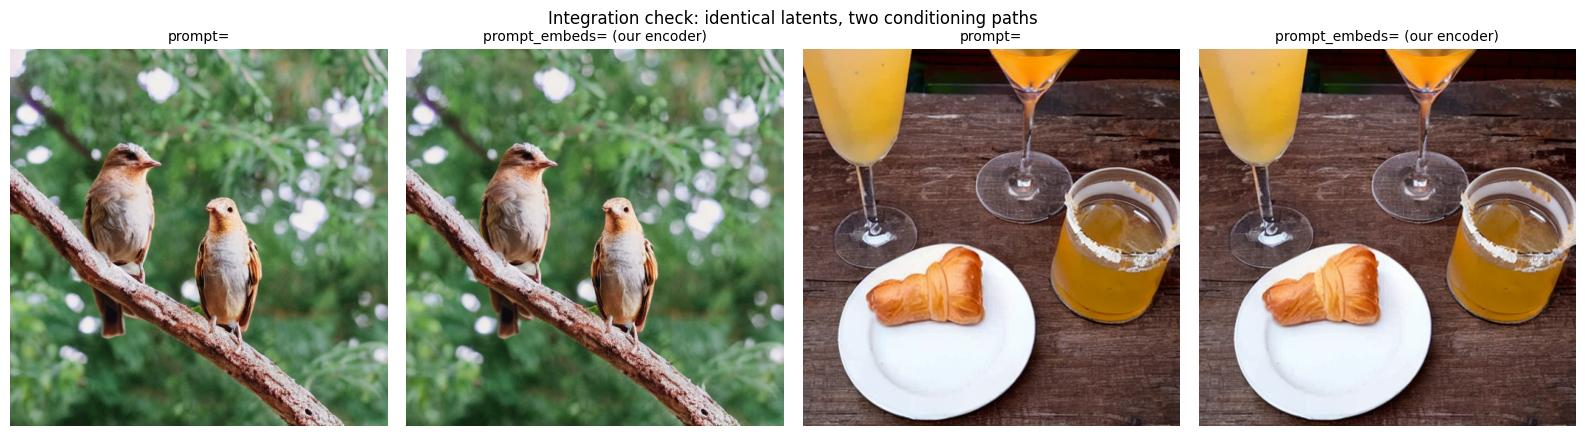

In [7]:
# Same two prompts, same latents, same settings: once through prompt=, once through our prompt_embeds=
check_idx = [0, 1]
pipe.scheduler = PNDMScheduler.from_config(BASE_SCHEDULER_CONFIG)
common = dict(latents=MAIN["latents"][check_idx].to(DEVICE, DTYPE), num_inference_steps=BASE["steps"],
              guidance_scale=BASE["cfg"], output_type="np")

with torch.no_grad():
    via_text = pipe(prompt=[prompts[i] for i in check_idx], **common).images
    via_embeds = pipe(prompt_embeds=MAIN["cond"][check_idx],
                      negative_prompt_embeds=UNCOND.expand(len(check_idx), -1, -1), **common).images

pixel_diff = np.abs(via_text - via_embeds)
print(f"pixel difference (0-1 scale): max {pixel_diff.max():.4f}, mean {pixel_diff.mean():.5f}")
assert pixel_diff.mean() < 0.01, "prompt_embeds path does not reproduce the prompt= path"

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for k, i in enumerate(check_idx):
    axes[2 * k].imshow(via_text[k]); axes[2 * k].set_title("prompt=", fontsize=10)
    axes[2 * k + 1].imshow(via_embeds[k]); axes[2 * k + 1].set_title("prompt_embeds= (our encoder)", fontsize=10)
for ax in axes:
    ax.axis("off")
fig.suptitle("Integration check: identical latents, two conditioning paths", fontsize=12)
plt.tight_layout()
plt.savefig(GRIDS_DIR / "integration_check.png", dpi=110, bbox_inches="tight")
plt.show()

## 5. Generation runner and log

`run_config` renders one prompt set under one configuration and appends a row per image to `LOG`:
every setting, the seconds per image and both scores. That log is the generation log the report
asks for. It is saved as `generation_log.csv` after every section, so a crash loses nothing already
generated.

In [8]:
SCHEDULERS = {
    "pndm": PNDMScheduler,
    "ddim": DDIMScheduler,
    "euler": EulerDiscreteScheduler,
    "euler_a": EulerAncestralDiscreteScheduler,  # ancestral: injects fresh noise at every step
    "dpmpp_2m": DPMSolverMultistepScheduler,     # DPM-Solver++ 2M
    "ddpm": DDPMScheduler,                       # the original DDPM sampler, also ancestral
}


def make_scheduler(name, **overrides):
    # Swap the sampler but keep SD v1.5's trained betas, unless a sweep overrides them on purpose
    return SCHEDULERS[name].from_config(BASE_SCHEDULER_CONFIG, **overrides)


@torch.no_grad()
def image_features(images):
    pixels = clip_processor(images=images, return_tensors="pt").pixel_values.to(DEVICE, DTYPE)
    feats = clip_model.visual_projection(clip_model.vision_model(pixel_values=pixels).pooler_output).float()
    return feats / feats.norm(dim=-1, keepdim=True)


@torch.no_grad()
def text_features(texts):
    ids = tokenizer(texts, **TOK_ARGS).input_ids.to(DEVICE)
    feats = clip_model.text_projection(clip_model.text_model(input_ids=ids).pooler_output).float()
    return feats / feats.norm(dim=-1, keepdim=True)


for ps in PROMPT_SETS.values():
    ps["text_feats"] = text_features(ps["prompts"])
    ps["real_images"] = [Image.open(p).convert("RGB") for p in ps["real_paths"]] if ps["has_real"] else None
    ps["real_feats"] = image_features(ps["real_images"]) if ps["has_real"] else None
    ps["real_clip"] = (100 * (ps["real_feats"] * ps["text_feats"]).sum(-1).clamp(min=0)).tolist() if ps["has_real"] else None

LOG = []    # one dict per generated image
RUNS = {}   # (experiment, config) -> {"images", "idx", "set"}
BASELINE_OF = {"main": ("baseline", "pndm_50_cfg7.5"), "heldout": ("heldout", "baseline")}


def baseline_scores(set_name):
    exp, cfgname = BASELINE_OF[set_name]
    return {r["prompt_id"]: r["clip_score"] for r in LOG
            if r["experiment"] == exp and r["config"] == cfgname and not r["nsfw_flagged"]}


def scored(rows):
    # The safety checker occasionally blacks out a harmless image (a false positive). A black image would
    # score near zero and say nothing about the setting under test, so flagged images stay in the log
    # but are left out of every average and every paired comparison.
    return [r for r in rows if not r["nsfw_flagged"]]


def run_config(experiment, config, sampler, steps, cfg, guidance_rescale=0.0, idx=None,
               scheduler_kwargs=None, ps=None, cond=None, uncond=None, encoder="clip"):
    ps = MAIN if ps is None else ps
    cond = ps["cond"] if cond is None else cond
    uncond = UNCOND if uncond is None else uncond
    idx = list(range(len(ps["prompts"]))) if idx is None else list(idx)
    scheduler_kwargs = scheduler_kwargs or {}
    pipe.scheduler = make_scheduler(sampler, **scheduler_kwargs)
    folder = IMAGES_DIR / experiment / config
    folder.mkdir(parents=True, exist_ok=True)

    images = []
    for start in range(0, len(idx), BATCH):
        part = idx[start:start + BATCH]
        # Ancestral samplers draw extra noise each step; seeded CPU generators make that reproducible too
        generators = [torch.Generator("cpu").manual_seed(ps["seed"] + 1 + i) for i in part]
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.no_grad():
            out = pipe(
                prompt_embeds=cond[part],
                negative_prompt_embeds=uncond.expand(len(part), -1, -1),
                latents=ps["latents"][part].to(DEVICE, DTYPE),
                num_inference_steps=steps,
                guidance_scale=cfg,
                guidance_rescale=guidance_rescale,
                generator=generators,
            )
        torch.cuda.synchronize()
        sec = (time.perf_counter() - t0) / len(part)

        feats = image_features(out.images)
        clip_scores = (100 * (feats * ps["text_feats"][part]).sum(-1).clamp(min=0)).tolist()
        real_sims = (feats * ps["real_feats"][part]).sum(-1).tolist() if ps["has_real"] else [None] * len(part)
        nsfw = out.nsfw_content_detected or [False] * len(part)

        for i, img, cs, rs, flagged in zip(part, out.images, clip_scores, real_sims, nsfw):
            path = folder / f"{ps['name']}_p{i:02d}.png"
            img.save(path)
            LOG.append({
                "experiment": experiment, "config": config, "prompt_set": ps["name"], "encoder": encoder,
                "sampler": sampler, "steps": steps, "cfg": cfg, "guidance_rescale": guidance_rescale,
                "beta_schedule": scheduler_kwargs.get("beta_schedule", BASE_SCHEDULER_CONFIG["beta_schedule"]),
                "timestep_spacing": scheduler_kwargs.get("timestep_spacing", BASE_SCHEDULER_CONFIG.get("timestep_spacing", "leading")),
                "karras_sigmas": scheduler_kwargs.get("use_karras_sigmas", False),
                "prompt_id": i, "prompt": ps["prompts"][i], "latent_seed": ps["seed"], "noise_seed": ps["seed"] + 1 + i,
                "seconds_per_image": round(sec, 3), "clip_score": round(cs, 2),
                "real_similarity": None if rs is None else round(rs, 4),
                "nsfw_flagged": bool(flagged), "file": str(path.relative_to(OUT_DIR)),
            })
        images.extend(out.images)

    RUNS[(experiment, config)] = {"images": images, "idx": idx, "set": ps["name"]}

    all_rows = [r for r in LOG if r["experiment"] == experiment and r["config"] == config]
    rows = scored(all_rows)
    base = baseline_scores(ps["name"])
    deltas = [r["clip_score"] - base[r["prompt_id"]] for r in rows if r["prompt_id"] in base]
    delta_txt = f" | vs baseline {np.mean(deltas):+5.2f}" if deltas and (experiment, config) != BASELINE_OF[ps["name"]] else ""
    real_txt = f" | real-sim {np.mean([r['real_similarity'] for r in rows]):.3f}" if ps["has_real"] else ""
    flag_txt = f" | {len(all_rows) - len(rows)} blocked by safety filter" if len(rows) < len(all_rows) else ""
    print(f"[{experiment:>9}] {config:<28} CLIP {np.mean([r['clip_score'] for r in rows]):5.2f}"
          f"{delta_txt}{real_txt} | {np.mean([r['seconds_per_image'] for r in all_rows]):6.2f} s/img{flag_txt}")
    return images


def save_log():
    pd.DataFrame(LOG).to_csv(OUT_DIR / "generation_log.csv", index=False)


def paired_table(df, keys):
    # Mean scores per configuration, plus the prompt-by-prompt difference from the baseline of the same
    # prompt set and its standard error. A difference smaller than about 2 standard errors is noise.
    # Baseline scores always come from the full log, whichever rows `df` holds.
    full = pd.DataFrame(LOG)
    full = full[~full["nsfw_flagged"]]
    base = {}
    for set_name, (exp, cfgname) in BASELINE_OF.items():
        b = full[(full["experiment"] == exp) & (full["config"] == cfgname)]
        base.update({(set_name, p): s for p, s in zip(b["prompt_id"], b["clip_score"])})
    flagged = df[df["nsfw_flagged"]].groupby(keys, sort=False).size()
    df = df[~df["nsfw_flagged"]]
    df = df.assign(delta=[r.clip_score - base.get((r.prompt_set, r.prompt_id), np.nan) for r in df.itertuples()])
    table = df.groupby(keys, sort=False).agg(
        clip_score=("clip_score", "mean"),
        vs_baseline=("delta", "mean"),
        vs_baseline_se=("delta", lambda d: d.std(ddof=1) / np.sqrt(d.count()) if d.count() > 1 else np.nan),
        real_similarity=("real_similarity", "mean"),
        seconds_per_image=("seconds_per_image", "mean"),
        n_scored=("clip_score", "size"),
    )
    table["n_safety_blocked"] = flagged.reindex(table.index).fillna(0).astype(int)
    return table.round(3)


def summarize(experiment):
    table = paired_table(pd.DataFrame([r for r in LOG if r["experiment"] == experiment]), "config")
    table.to_csv(TABLES_DIR / f"{experiment}.csv")
    return table


def show_grid(keys, title, filename):
    # keys: list of (experiment, config); all must share one prompt set and the same prompts
    first = RUNS[keys[0]]
    ps, idx = PROMPT_SETS[first["set"]], first["idx"]
    with_real = ps["has_real"]
    n_rows, cols = len(idx), len(keys) + int(with_real)
    fig, axes = plt.subplots(n_rows, cols, figsize=(2.2 * cols + 1.6, 2.2 * n_rows + 0.8), squeeze=False)
    for c, key in enumerate(keys):
        rows = [r for r in LOG if (r["experiment"], r["config"]) == key]
        axes[0, c].set_title(f"{key[1]}\nCLIP {np.mean([r['clip_score'] for r in scored(rows)]):.1f}", fontsize=9)
        for r in range(n_rows):
            axes[r, c].imshow(RUNS[key]["images"][r])
            if rows[r]["nsfw_flagged"]:
                axes[r, c].text(0.5, 0.5, "blocked by\nsafety filter\n(false positive)", color="white",
                                ha="center", va="center", fontsize=8, transform=axes[r, c].transAxes)
    if with_real:
        axes[0, -1].set_title("real COCO photo", fontsize=9)
        for r, i in enumerate(idx):
            axes[r, -1].imshow(ps["real_images"][i])
    for r, i in enumerate(idx):
        axes[r, 0].text(-0.05, 0.5, textwrap.fill(ps["prompts"][i], 24), transform=axes[r, 0].transAxes,
                        ha="right", va="center", fontsize=7.5)
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(textwrap.fill(title, 14 * cols), fontsize=12)
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.9 / fig.get_figheight()))
    plt.savefig(GRIDS_DIR / f"{filename}.png", dpi=80, bbox_inches="tight")
    plt.show()

## 6. Baseline conditional generation

The control everything else is measured against: SD v1.5's own pipeline defaults, which are the
PNDM sampler, 50 steps and guidance 7.5.

[ baseline] pndm_50_cfg7.5               CLIP 27.03 | real-sim 0.754 |   6.40 s/img


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
config,,,,,,,
pndm_50_cfg7.5,27.026,0.0,0.0,0.754,6.398,10,0


real COCO photos against the same prompts: CLIP 23.59


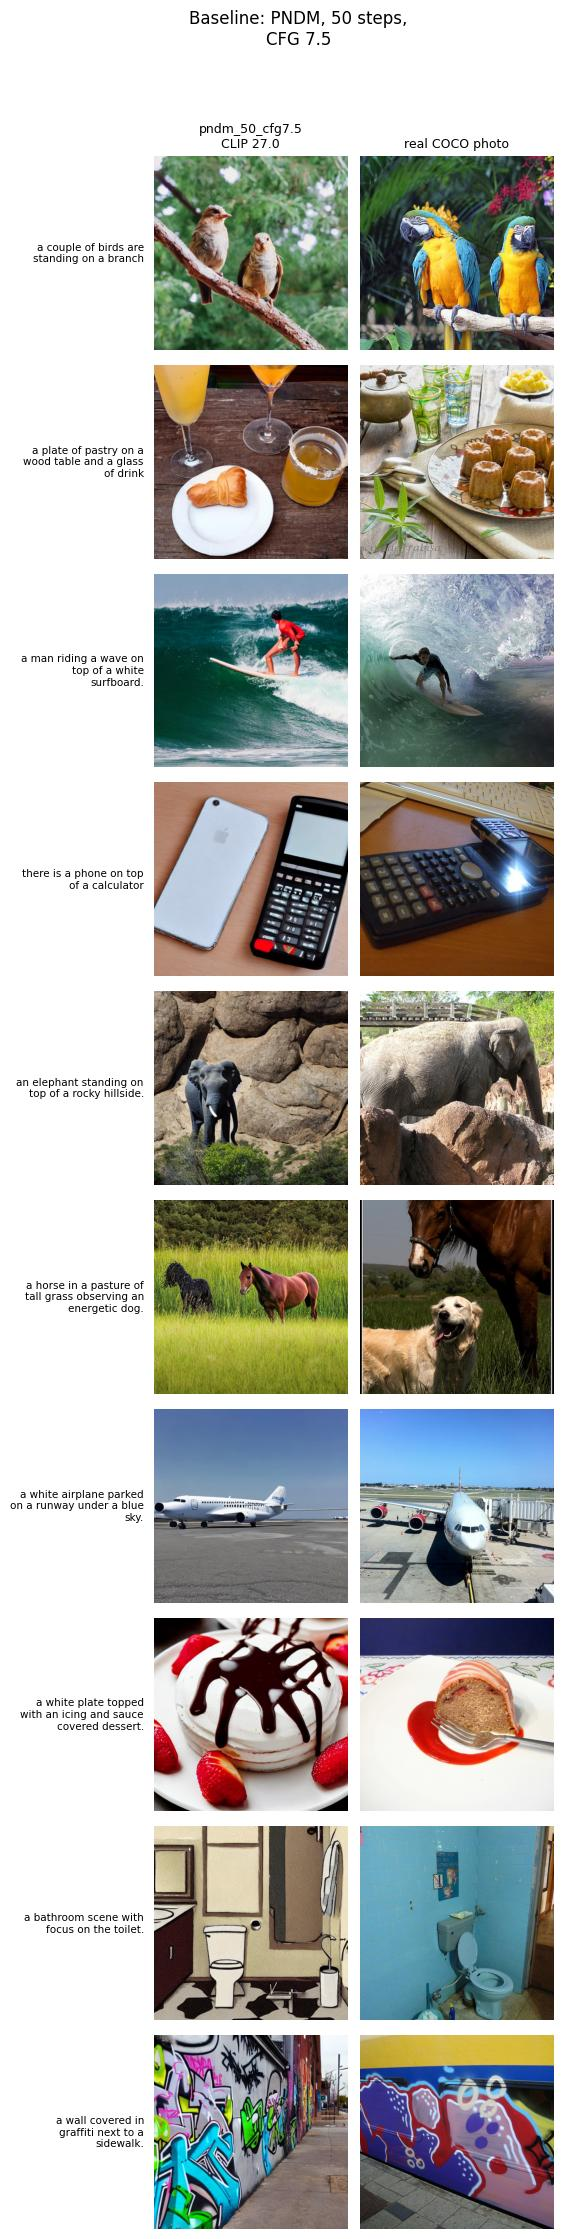

In [9]:
run_config("baseline", "pndm_50_cfg7.5", BASE["sampler"], BASE["steps"], BASE["cfg"])
save_log()
display(summarize("baseline"))
print(f"real COCO photos against the same prompts: CLIP {np.mean(MAIN['real_clip']):.2f}")
show_grid([("baseline", "pndm_50_cfg7.5")], "Baseline: PNDM, 50 steps, CFG 7.5", "baseline")

## 7. Classifier-free guidance sweep

The guidance scale `w` sets how hard each step is pushed toward the prompt:
`noise = uncond + w · (cond − uncond)`. At `w = 1` there is no guidance, only the conditional
prediction. Higher values follow the prompt more closely but, past a point, oversaturate colour and
flatten detail. Sampler and steps stay at the baseline's (PNDM, 50).

The last configuration repeats the highest scale with `guidance_rescale = 0.7`, which rescales the
guided prediction back toward the spread of the conditional one to undo the oversaturation.

[      cfg] cfg_1                        CLIP 22.76 | vs baseline -4.26 | real-sim 0.662 |   3.63 s/img
[      cfg] cfg_3                        CLIP 25.96 | vs baseline -1.07 | real-sim 0.721 |   7.02 s/img
[      cfg] cfg_5                        CLIP 26.50 | vs baseline -0.53 | real-sim 0.746 |   7.29 s/img
[      cfg] cfg_7.5                      CLIP 27.03 | vs baseline +0.00 | real-sim 0.754 |   7.53 s/img
[      cfg] cfg_10                       CLIP 26.40 | vs baseline -0.63 | real-sim 0.746 |   7.53 s/img
[      cfg] cfg_15                       CLIP 26.12 | vs baseline -0.91 | real-sim 0.736 |   7.49 s/img
[      cfg] cfg_15_rescale0.7            CLIP 26.29 | vs baseline -0.74 | real-sim 0.747 |   7.55 s/img


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
config,,,,,,,
cfg_1,22.764,-4.262,1.062,0.662,3.626,10,0
cfg_3,25.958,-1.068,0.841,0.721,7.018,10,0
cfg_5,26.497,-0.529,0.513,0.746,7.290,10,0
cfg_7.5,27.026,0.000,0.000,0.754,7.532,10,0
cfg_10,26.401,-0.625,0.787,0.746,7.532,10,0
cfg_15,26.120,-0.906,0.944,0.736,7.492,10,0
cfg_15_rescale0.7,26.288,-0.738,0.786,0.747,7.546,10,0


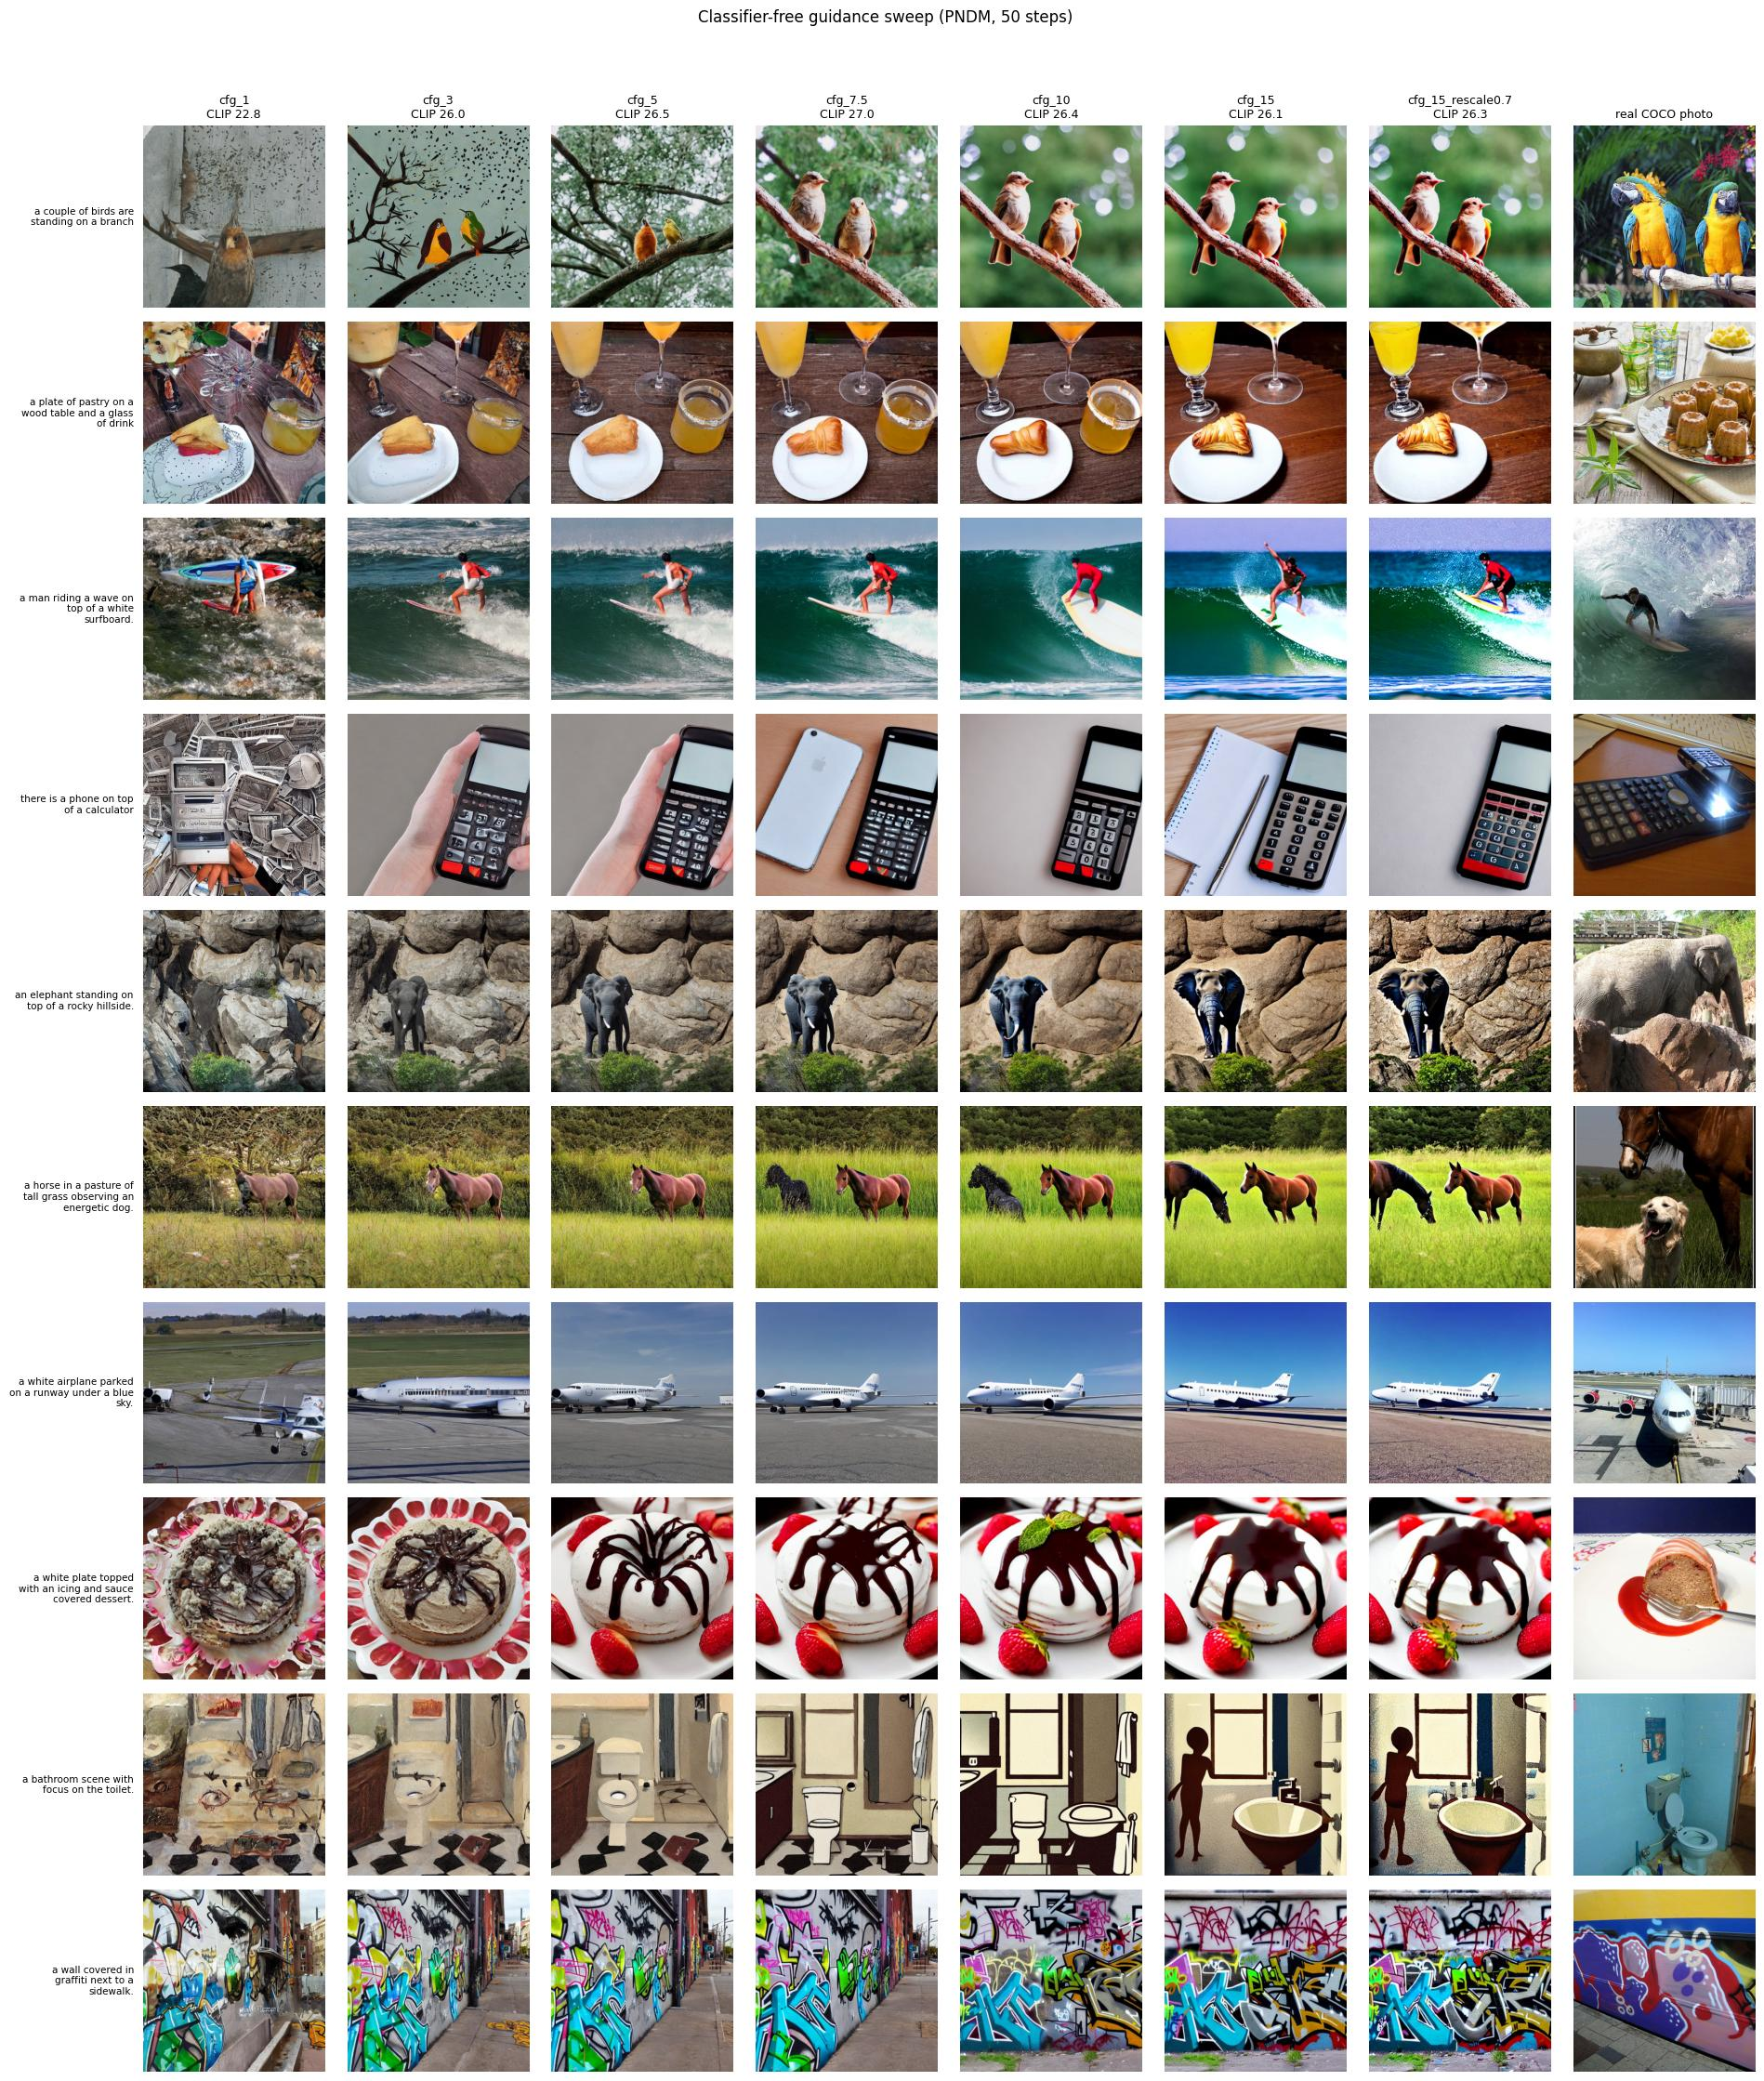

In [10]:
cfg_configs = []
for w in CFG_VALUES:
    run_config("cfg", f"cfg_{w:g}", BASE["sampler"], BASE["steps"], w)
    cfg_configs.append(f"cfg_{w:g}")
w_max = max(CFG_VALUES)
rescaled = f"cfg_{w_max:g}_rescale{RESCALE_AT_HIGH_CFG:g}"
run_config("cfg", rescaled, BASE["sampler"], BASE["steps"], w_max, guidance_rescale=RESCALE_AT_HIGH_CFG)
cfg_configs.append(rescaled)

save_log()
cfg_table = summarize("cfg")
display(cfg_table)
show_grid([("cfg", c) for c in cfg_configs], "Classifier-free guidance sweep (PNDM, 50 steps)", "cfg")

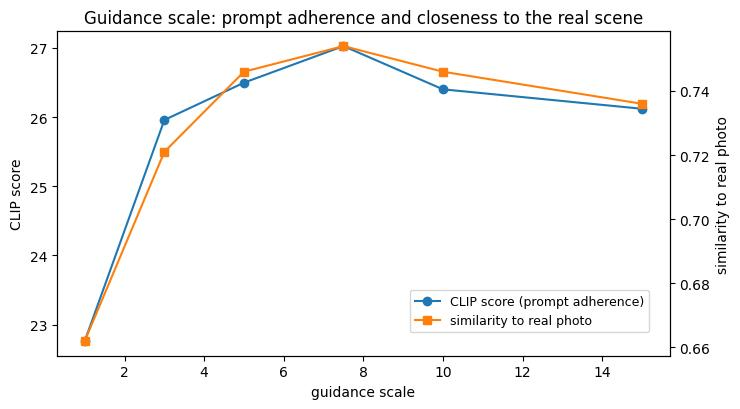

In [11]:
plain = cfg_table.loc[[f"cfg_{w:g}" for w in CFG_VALUES]]
fig, ax1 = plt.subplots(figsize=(7.5, 4.2))
ax1.plot(CFG_VALUES, plain["clip_score"], marker="o", label="CLIP score (prompt adherence)")
ax1.set_xlabel("guidance scale")
ax1.set_ylabel("CLIP score")
ax2 = ax1.twinx()
ax2.plot(CFG_VALUES, plain["real_similarity"], marker="s", color="tab:orange", label="similarity to real photo")
ax2.set_ylabel("similarity to real photo")
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.18), fontsize=9)
ax1.set_title("Guidance scale: prompt adherence and closeness to the real scene")
plt.tight_layout()
plt.savefig(GRIDS_DIR / "cfg_curve.png", dpi=110, bbox_inches="tight")
plt.show()

## 8. Noise schedule

"Noise schedule" covers several related settings. Each is swept on its own, with guidance at 7.5:

| Sweep | What it changes | Held fixed |
|---|---|---|
| 8a. Sampler | The solver that walks down the noise levels: PNDM, DDIM, Euler, Euler ancestral, DPM-Solver++ 2M, DDPM | 30 steps, trained betas |
| 8b. Beta schedule | How noise variance grows over the 1,000 training timesteps: `scaled_linear` (what SD v1.5 was trained with), `linear`, `squaredcos_cap_v2` | DDIM, 30 steps |
| 8c. Timestep spacing | Which 30 of the 1,000 timesteps are visited: `leading`, `linspace`, `trailing` | DDIM, 30 steps |
| 8d. Step count | How many noise levels are visited: 10, 20, 30, 50, plus Karras sigma spacing at 10 | DPM-Solver++ 2M |

Sweep 8b is a stress test rather than a search for a better setting. The UNet learned to remove noise
at the `scaled_linear` levels, so any other schedule asks it to denoise at levels it never saw in
training.

[  sampler] pndm                         CLIP 25.62 | vs baseline -1.41 | real-sim 0.736 |   4.63 s/img
[  sampler] ddim                         CLIP 25.82 | vs baseline -1.20 | real-sim 0.749 |   4.53 s/img
[  sampler] euler                        CLIP 26.77 | vs baseline -0.25 | real-sim 0.750 |   4.50 s/img
[  sampler] euler_a                      CLIP 27.11 | vs baseline +0.09 | real-sim 0.769 |   4.49 s/img
[  sampler] dpmpp_2m                     CLIP 26.46 | vs baseline -0.57 | real-sim 0.739 |   4.52 s/img
[  sampler] ddpm                         CLIP 26.33 | vs baseline -0.70 | real-sim 0.765 |   4.53 s/img


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
config,,,,,,,
pndm,25.619,-1.407,0.647,0.736,4.627,10,0
ddim,25.824,-1.202,0.706,0.749,4.534,10,0
euler,26.774,-0.252,0.526,0.750,4.499,10,0
euler_a,27.113,0.087,1.393,0.769,4.493,10,0
dpmpp_2m,26.457,-0.569,0.560,0.739,4.520,10,0
ddpm,26.329,-0.697,1.361,0.765,4.534,10,0


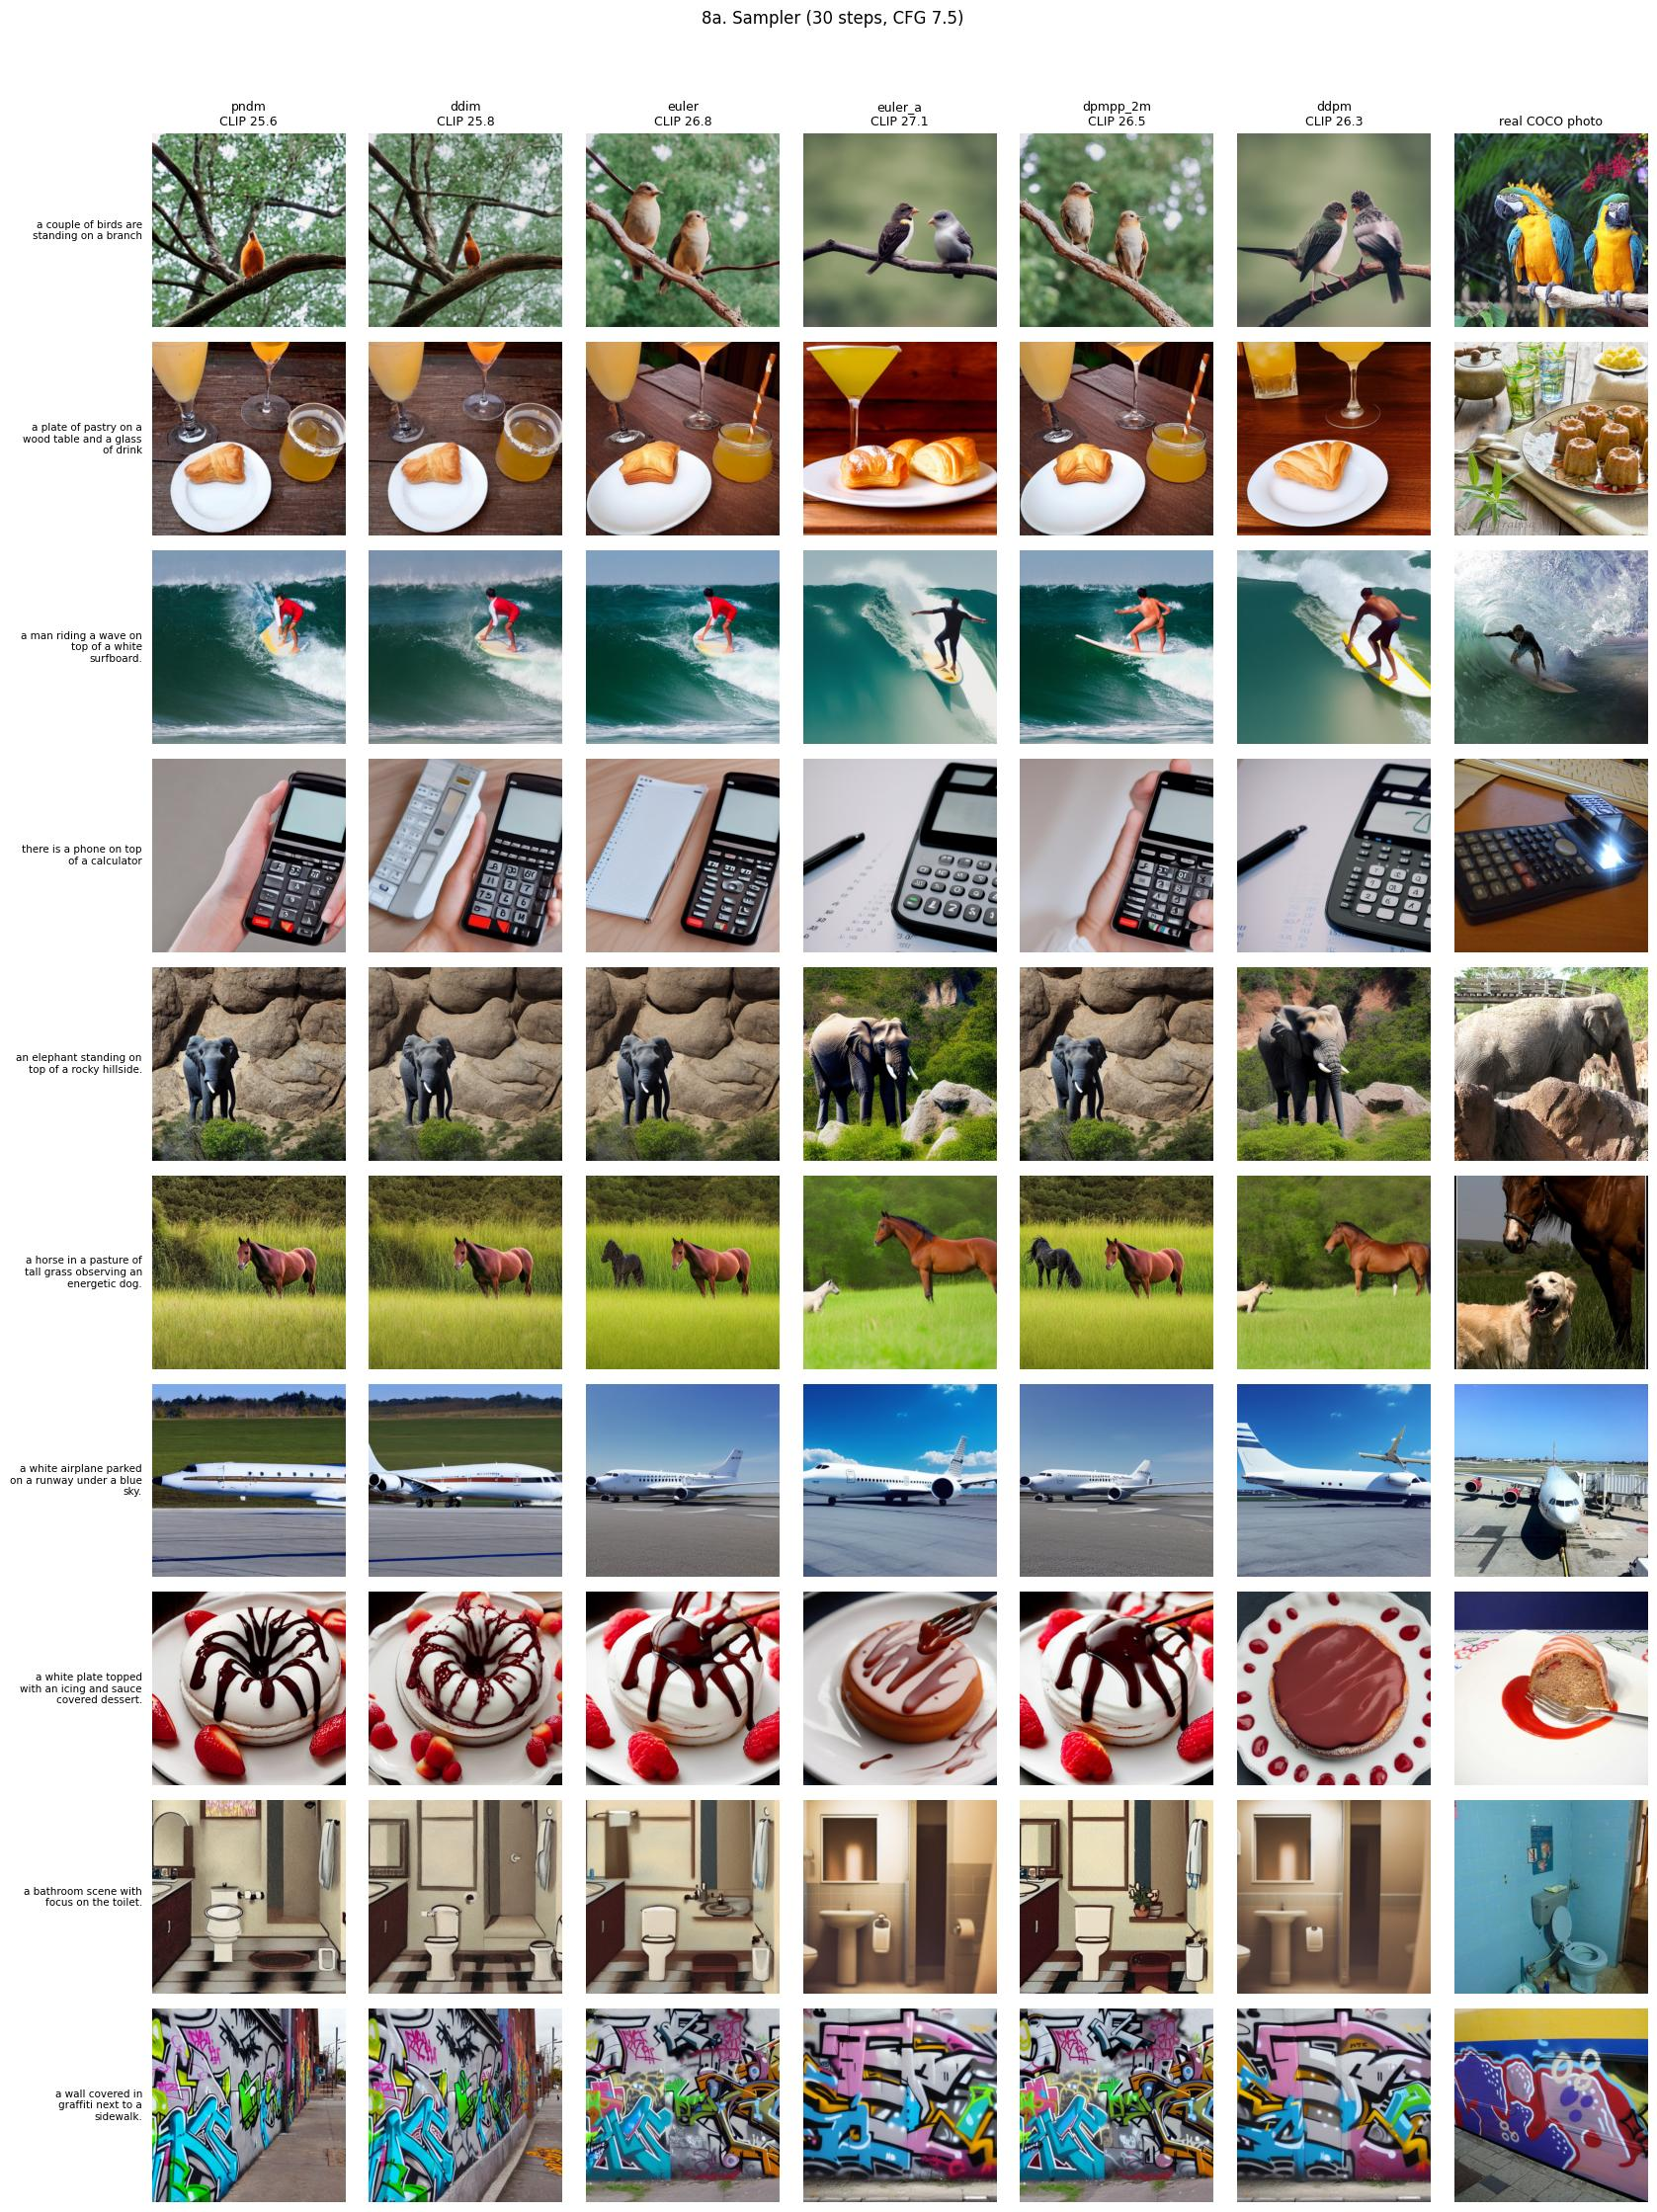

In [12]:
for s in SAMPLERS:
    run_config("sampler", s, s, SAMPLER_STEPS, BASE["cfg"])
save_log()
sampler_table = summarize("sampler")
display(sampler_table)
show_grid([("sampler", s) for s in SAMPLERS], f"8a. Sampler ({SAMPLER_STEPS} steps, CFG 7.5)", "sampler")

[     beta] scaled_linear                CLIP 25.82 | vs baseline -1.20 | real-sim 0.749 |   4.49 s/img
[     beta] linear                       CLIP 26.38 | vs baseline -0.65 | real-sim 0.741 |   4.50 s/img
[     beta] squaredcos_cap_v2            CLIP 26.10 | vs baseline -0.93 | real-sim 0.733 |   4.52 s/img


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
config,,,,,,,
scaled_linear,25.824,-1.202,0.706,0.749,4.488,10,0
linear,26.377,-0.649,0.817,0.741,4.496,10,0
squaredcos_cap_v2,26.100,-0.926,0.969,0.733,4.523,10,0


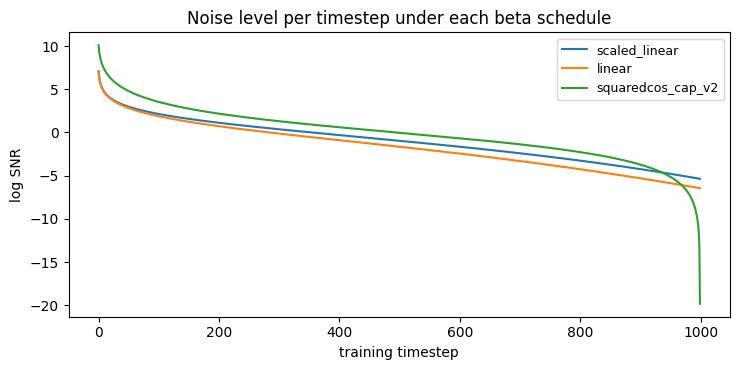

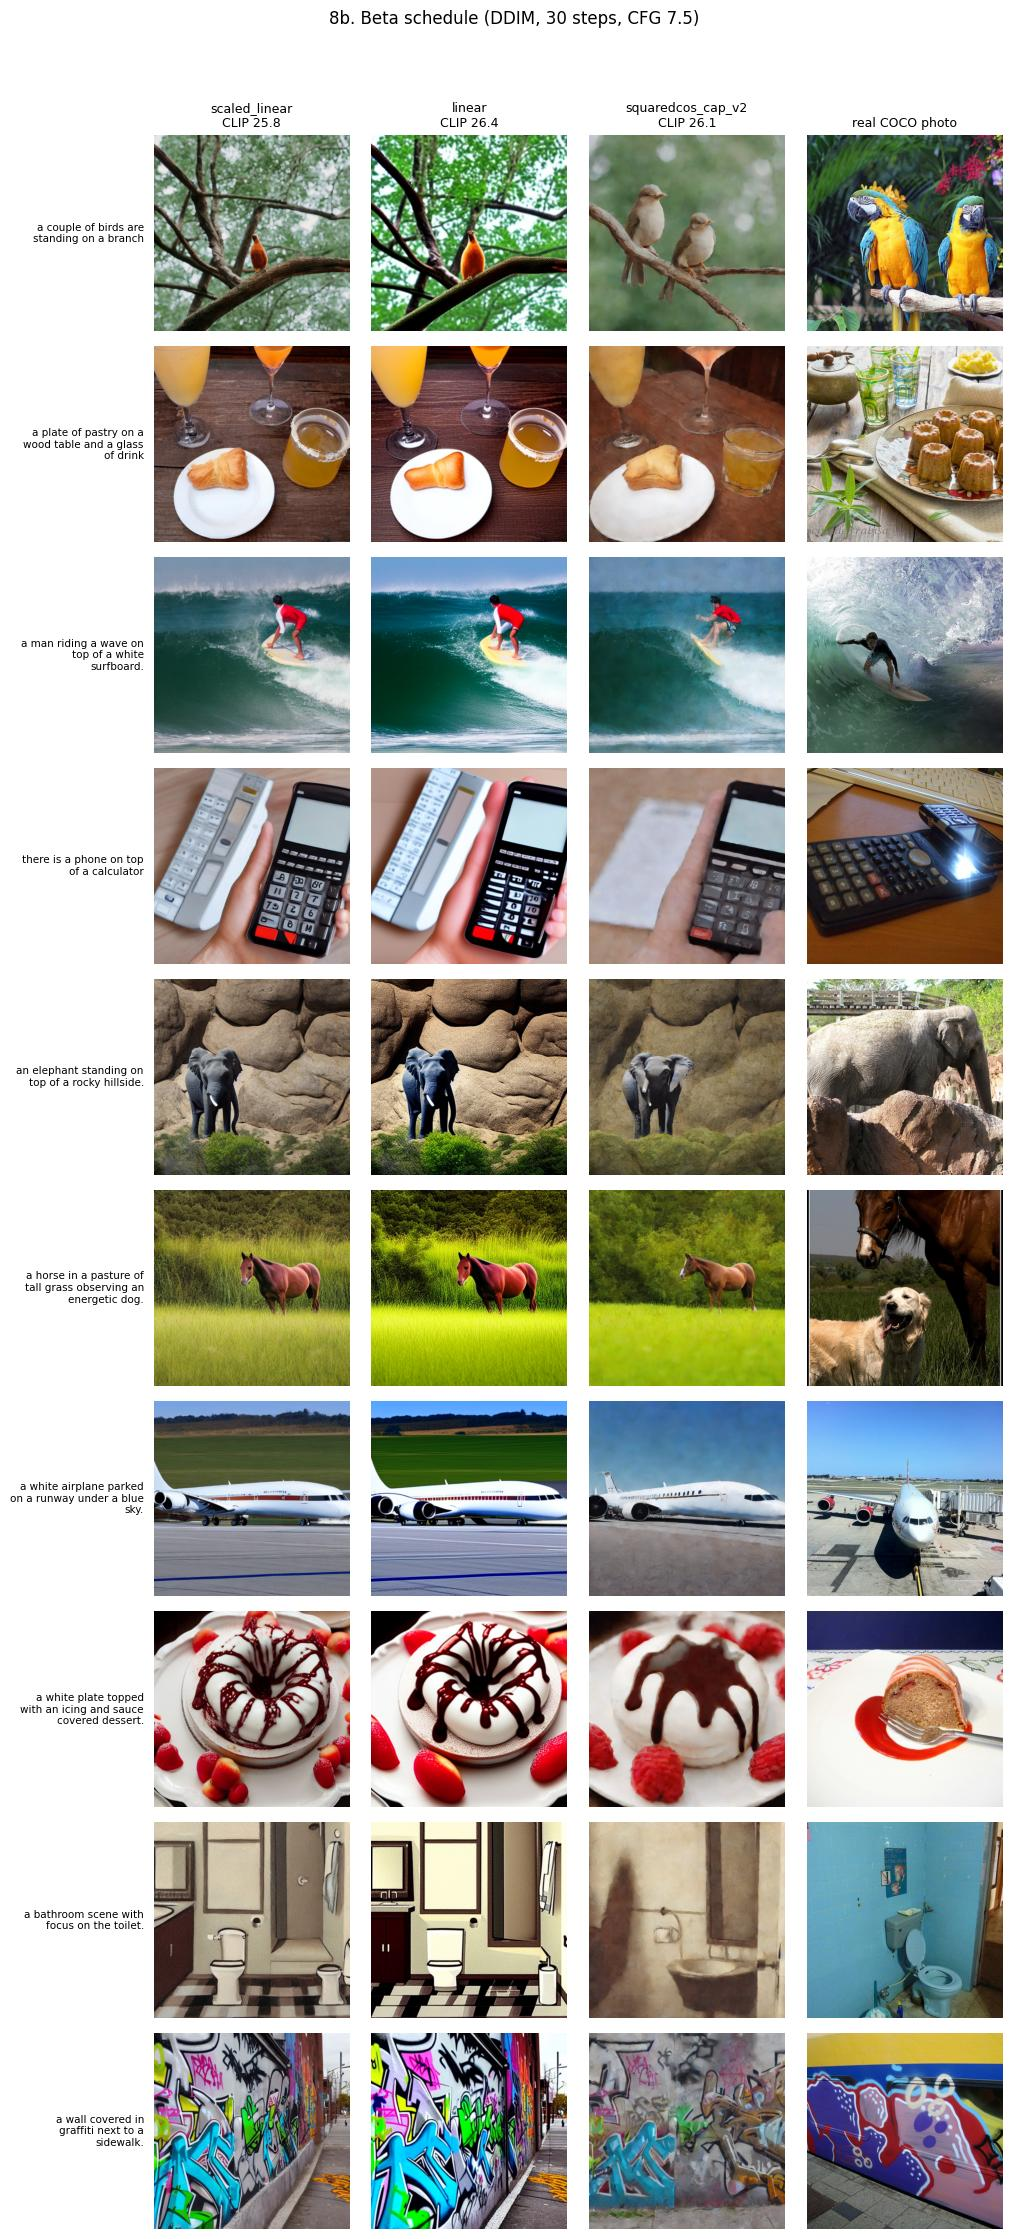

In [13]:
for b in BETA_SCHEDULES:
    run_config("beta", b, SCHEDULE_SAMPLER, SCHEDULE_STEPS, BASE["cfg"], scheduler_kwargs={"beta_schedule": b})
save_log()
beta_table = summarize("beta")
display(beta_table)

# What each schedule does to the noise level: signal-to-noise ratio across the training timesteps
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for b in BETA_SCHEDULES:
    alphas_bar = make_scheduler(SCHEDULE_SAMPLER, beta_schedule=b).alphas_cumprod
    ax.plot(torch.log(alphas_bar / (1 - alphas_bar)).numpy(), label=b)
ax.set_xlabel("training timestep")
ax.set_ylabel("log SNR")
ax.set_title("Noise level per timestep under each beta schedule")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(GRIDS_DIR / "beta_snr.png", dpi=110, bbox_inches="tight")
plt.show()

show_grid([("beta", b) for b in BETA_SCHEDULES], f"8b. Beta schedule (DDIM, {SCHEDULE_STEPS} steps, CFG 7.5)", "beta")

  leading: first [958, 925, 892] ... last [67, 34, 1]
 linspace: first [999, 965, 930] ... last [69, 34, 0]
 trailing: first [999, 966, 932] ... last [99, 66, 32]
[  spacing] leading                      CLIP 25.82 | vs baseline -1.20 | real-sim 0.749 |   4.49 s/img
[  spacing] linspace                     CLIP 26.29 | vs baseline -0.73 | real-sim 0.752 |   4.49 s/img
[  spacing] trailing                     CLIP 27.09 | vs baseline +0.07 | real-sim 0.759 |   4.52 s/img


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
config,,,,,,,
leading,25.824,-1.202,0.706,0.749,4.490,10,0
linspace,26.294,-0.732,0.696,0.752,4.494,10,0
trailing,27.094,0.068,0.445,0.759,4.517,10,0


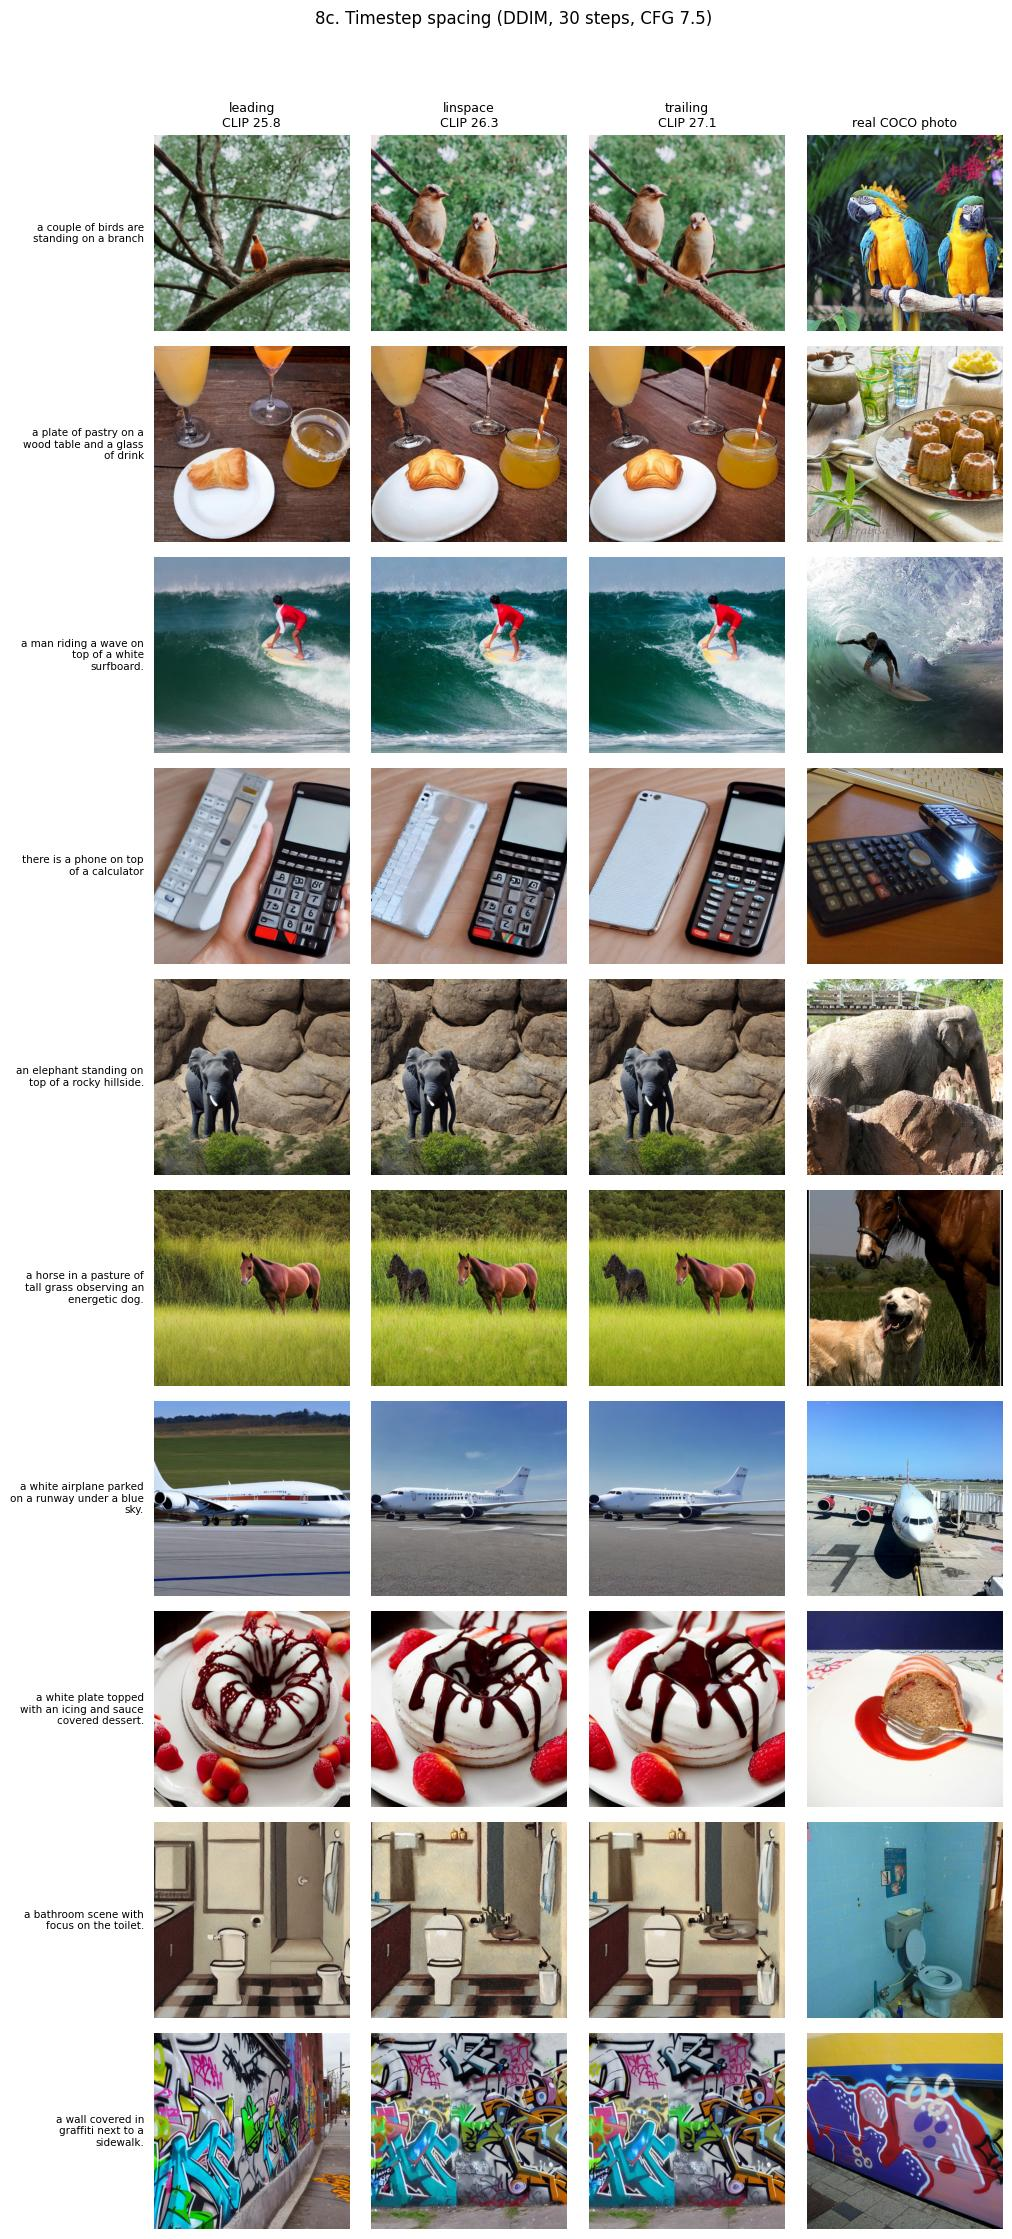

In [14]:
for sp in TIMESTEP_SPACINGS:
    sched = make_scheduler(SCHEDULE_SAMPLER, timestep_spacing=sp)
    sched.set_timesteps(SCHEDULE_STEPS)
    t = sched.timesteps.tolist()
    print(f"{sp:>9}: first {t[:3]} ... last {t[-3:]}")
for sp in TIMESTEP_SPACINGS:
    run_config("spacing", sp, SCHEDULE_SAMPLER, SCHEDULE_STEPS, BASE["cfg"], scheduler_kwargs={"timestep_spacing": sp})
save_log()
spacing_table = summarize("spacing")
display(spacing_table)
show_grid([("spacing", sp) for sp in TIMESTEP_SPACINGS],
          f"8c. Timestep spacing (DDIM, {SCHEDULE_STEPS} steps, CFG 7.5)", "spacing")

[    steps] 10_steps                     CLIP 26.97 | vs baseline -0.06 | real-sim 0.756 |   1.65 s/img
[    steps] 20_steps                     CLIP 26.17 | vs baseline -0.86 | real-sim 0.743 |   3.07 s/img
[    steps] 30_steps                     CLIP 26.46 | vs baseline -0.57 | real-sim 0.739 |   4.51 s/img
[    steps] 50_steps                     CLIP 26.51 | vs baseline -0.52 | real-sim 0.735 |   7.39 s/img
[    steps] 10_steps_karras              CLIP 26.09 | vs baseline -0.94 | real-sim 0.751 |   1.66 s/img


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
config,,,,,,,
10_steps,26.967,-0.059,1.044,0.756,1.653,10,0
20_steps,26.167,-0.859,0.706,0.743,3.069,10,0
30_steps,26.457,-0.569,0.560,0.739,4.508,10,0
50_steps,26.507,-0.519,0.781,0.735,7.390,10,0
10_steps_karras,26.088,-0.938,0.689,0.751,1.661,10,0


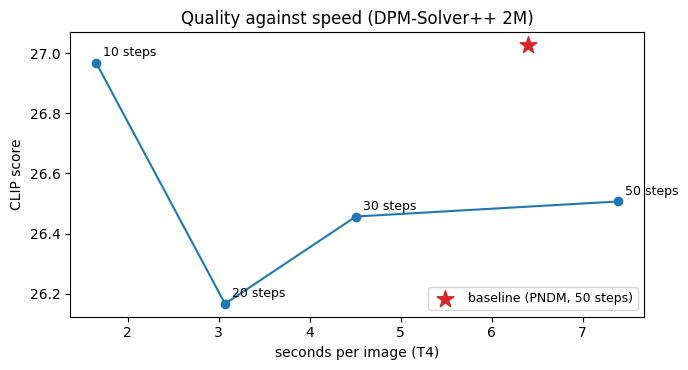

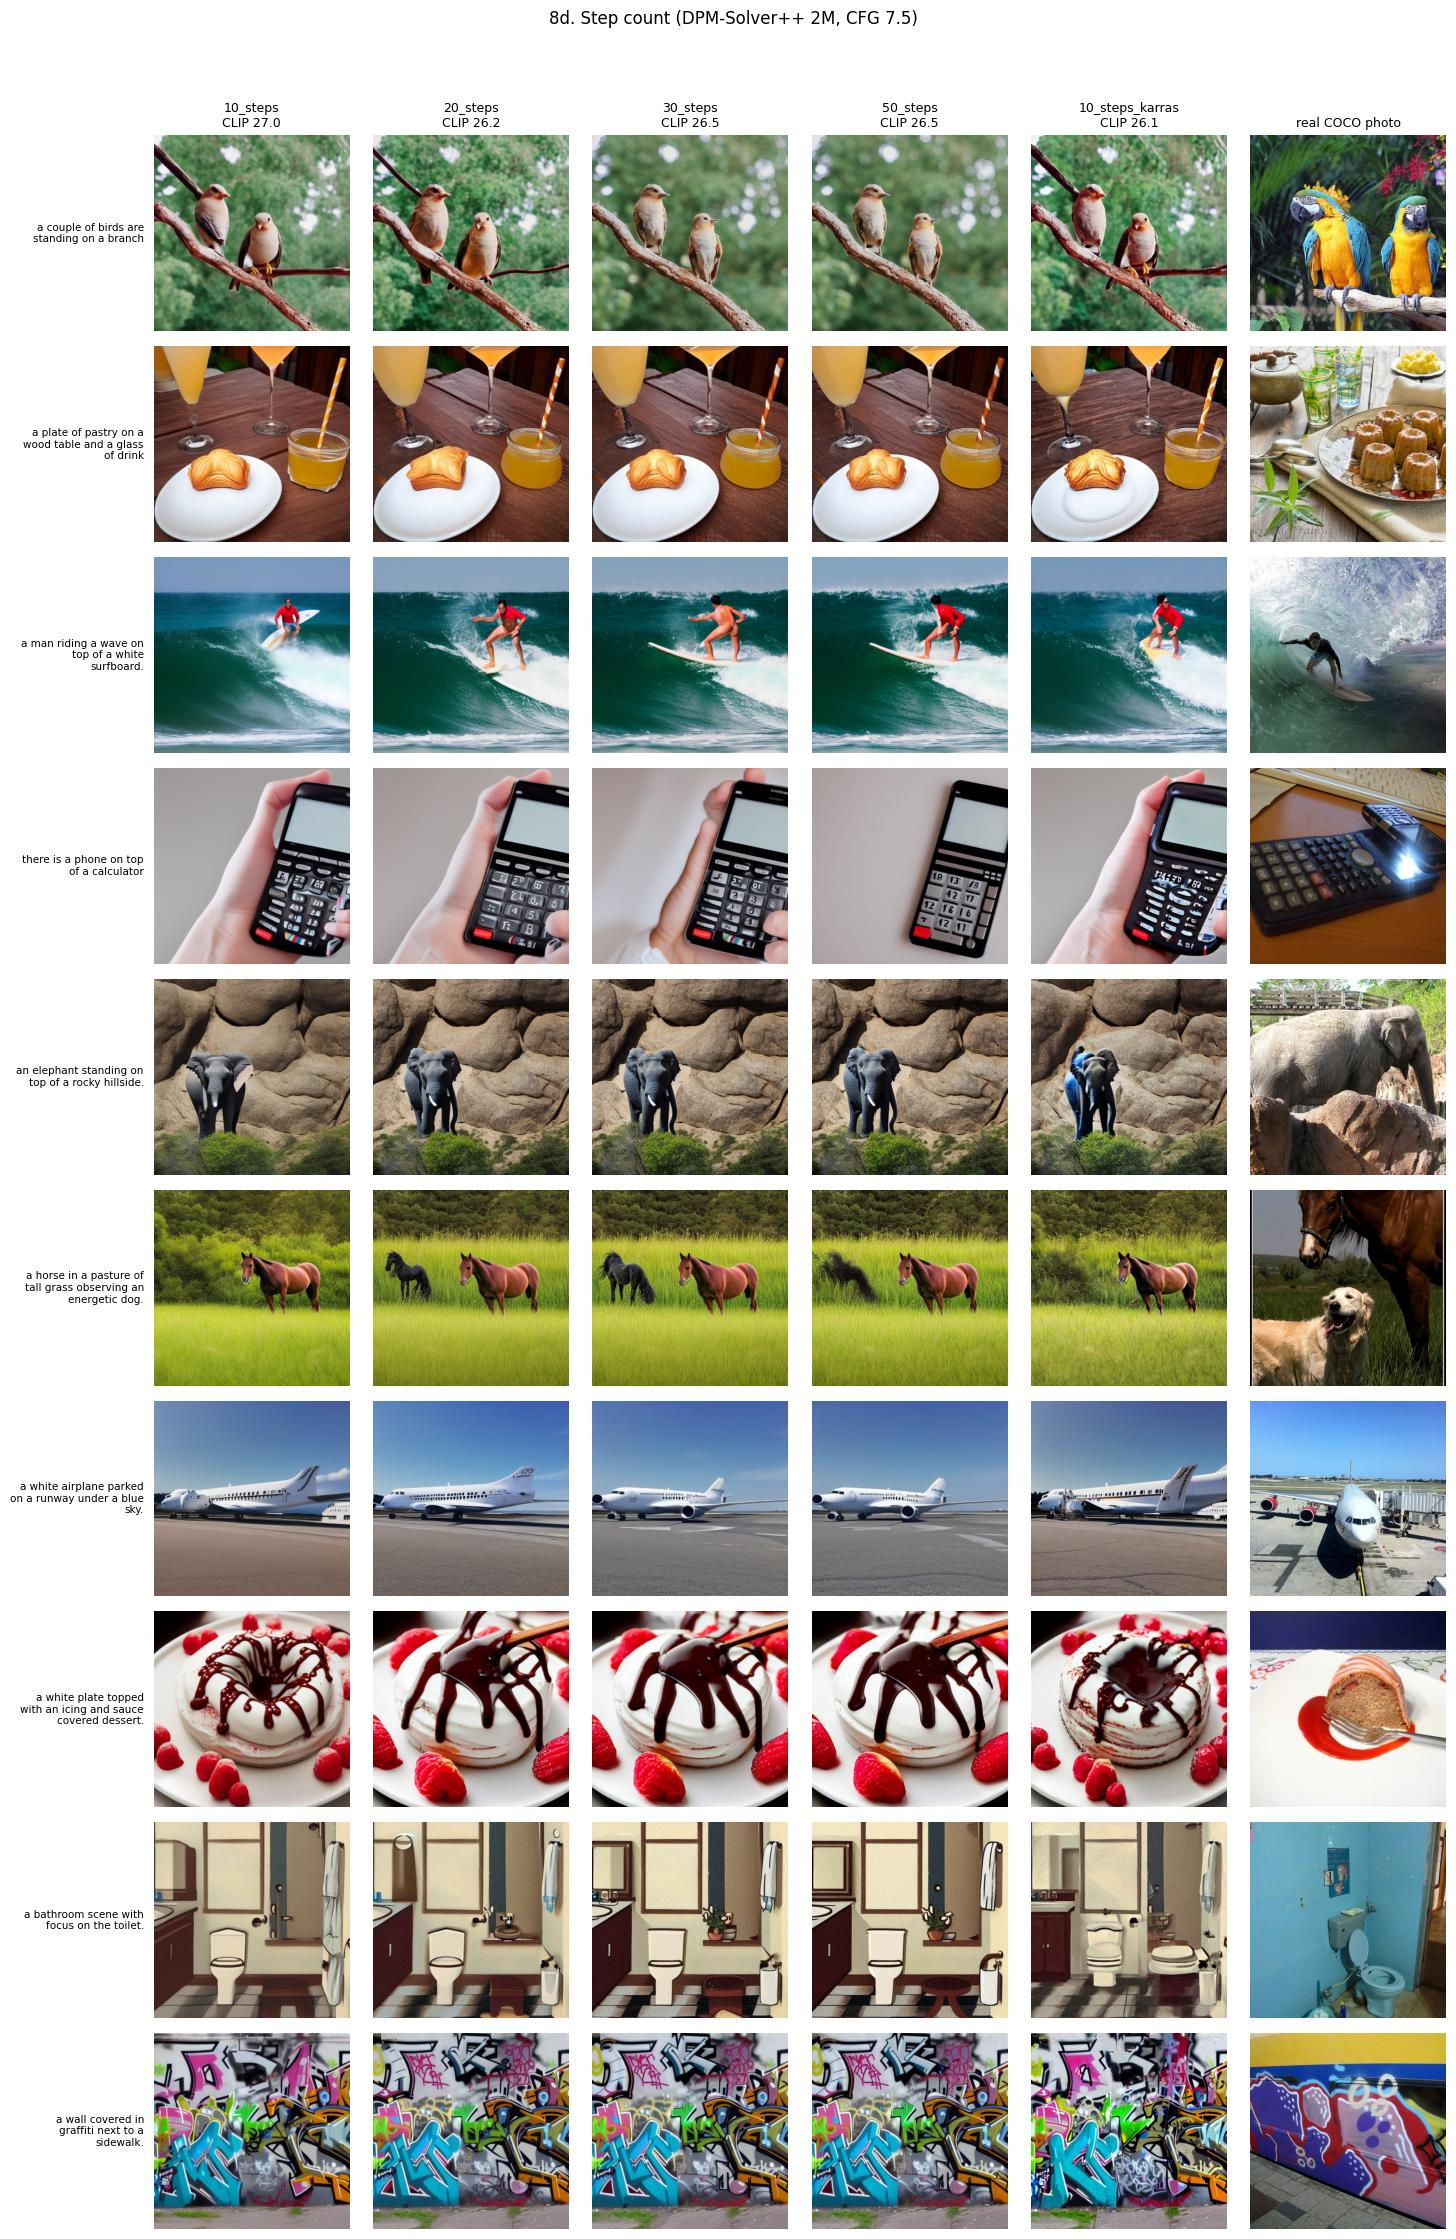

In [15]:
steps_configs = []
for n in STEP_COUNTS:
    run_config("steps", f"{n}_steps", STEPS_SAMPLER, n, BASE["cfg"])
    steps_configs.append(f"{n}_steps")
karras = f"{KARRAS_STEPS}_steps_karras"
run_config("steps", karras, STEPS_SAMPLER, KARRAS_STEPS, BASE["cfg"], scheduler_kwargs={"use_karras_sigmas": True})
steps_configs.append(karras)
save_log()
steps_table = summarize("steps")
display(steps_table)

plain_steps = steps_table.loc[[f"{n}_steps" for n in STEP_COUNTS]]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(plain_steps["seconds_per_image"], plain_steps["clip_score"], marker="o")
for n, (x, y) in zip(STEP_COUNTS, zip(plain_steps["seconds_per_image"], plain_steps["clip_score"])):
    ax.annotate(f"{n} steps", (x, y), textcoords="offset points", xytext=(5, 5), fontsize=9)
base_row = summarize("baseline").iloc[0]
ax.scatter([base_row["seconds_per_image"]], [base_row["clip_score"]], marker="*", s=160, color="tab:red",
           label="baseline (PNDM, 50 steps)")
ax.set_xlabel("seconds per image (T4)")
ax.set_ylabel("CLIP score")
ax.set_title("Quality against speed (DPM-Solver++ 2M)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(GRIDS_DIR / "steps_speed.png", dpi=110, bbox_inches="tight")
plt.show()

show_grid([("steps", c) for c in steps_configs], "8d. Step count (DPM-Solver++ 2M, CFG 7.5)", "steps")

## 9. DDPM: 1,000 steps against 20

DDPM is the sampler diffusion models were introduced with: it reverses every one of the 1,000
training timesteps. Modern solvers reach a comparable image in a small fraction of the steps. This
runs on 2 prompts only, since 1,000 steps costs about 50 times as much as 20.

[     ddpm] ddpm_1000                    CLIP 26.81 | vs baseline +0.87 | real-sim 0.744 | 146.92 s/img
[     ddpm] dpmpp_2m_20                  CLIP 27.18 | vs baseline +1.24 | real-sim 0.707 |   3.14 s/img


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
config,,,,,,,
ddpm_1000,26.810,0.875,1.185,0.744,146.921,2,0
dpmpp_2m_20,27.175,1.240,0.420,0.707,3.140,2,0


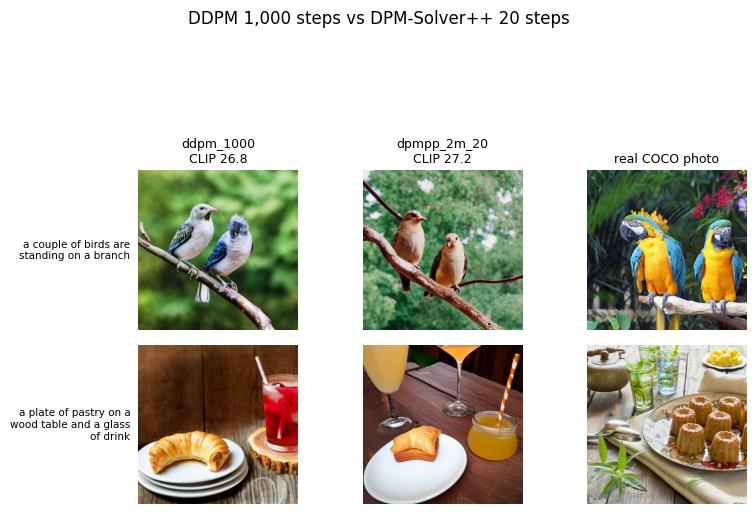

In [16]:
ddpm_idx = list(range(DDPM_N_PROMPTS))
# SD v1.5's config shifts every timestep by steps_offset=1; at all 1,000 steps that would ask for
# timestep 1000, one past the end of the 0-999 range, so the full run uses offset 0
run_config("ddpm", f"ddpm_{DDPM_FULL_STEPS}", "ddpm", DDPM_FULL_STEPS, BASE["cfg"], idx=ddpm_idx,
           scheduler_kwargs={"steps_offset": 0})
run_config("ddpm", "dpmpp_2m_20", "dpmpp_2m", 20, BASE["cfg"], idx=ddpm_idx)
save_log()
display(summarize("ddpm"))
show_grid([("ddpm", f"ddpm_{DDPM_FULL_STEPS}"), ("ddpm", "dpmpp_2m_20")],
          "DDPM 1,000 steps vs DPM-Solver++ 20 steps", "ddpm")

## 10. BERT as the text encoder

The brief lists BERT as an alternative encoder. BERT-base outputs 768-d token states, the same width
as CLIP's, so it can be plugged into the UNet's cross-attention directly. That alone does not work:
the UNet was trained on CLIP's embedding space, and BERT's space is unrelated to it. Milestone 1
measured the same gap from the other side (BERT barely separates two captions of one image from two
unrelated captions).

So we test BERT twice:

1. **Raw BERT**: BERT's 77 × 768 states passed straight in as `prompt_embeds`.
2. **BERT + adapter**: a small Transformer we train to translate BERT's states into CLIP's
   conditioning space. Everything else stays frozen: BERT, CLIP and the whole diffusion model.

The adapter is trained by distillation. For each training caption, CLIP's 77 × 768 output is the
target and BERT's output is the input; the loss is the mean squared error between the two. No UNet,
VAE or diffusion step is involved in training, which is why it takes minutes. CLIP is used only to
produce targets; at generation time the conditioning comes from BERT and the adapter alone.

The adapter cannot simply map position *i* to position *i*, because BERT and CLIP split words into
different tokens. Instead it holds 77 learned query vectors, one per CLIP position, which attend over
all of BERT's tokens and to each other.

In [17]:
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_ID)
bert = AutoModel.from_pretrained(BERT_MODEL_ID, torch_dtype=DTYPE).to(DEVICE).eval()


@torch.no_grad()
def bert_encode(texts):
    toks = bert_tokenizer(texts, padding="max_length", max_length=SEQ_LEN, truncation=True,
                          return_tensors="pt").to(DEVICE)
    return bert(**toks).last_hidden_state, toks["attention_mask"].bool()


raw_cond, _ = bert_encode(MAIN["prompts"])
raw_uncond, _ = bert_encode([""])
print(f"BERT states: {tuple(raw_cond.shape)}, mean |value| {raw_cond.abs().float().mean():.3f}")
print(f"CLIP states: {tuple(MAIN['cond'].shape)}, mean |value| {MAIN['cond'].abs().float().mean():.3f}")

run_config("bert", "bert_raw", BASE["sampler"], BASE["steps"], BASE["cfg"],
           cond=raw_cond, uncond=raw_uncond, encoder="bert_raw")
save_log()

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BERT states: (10, 77, 768), mean |value| 0.271
CLIP states: (10, 77, 768), mean |value| 0.772
[     bert] bert_raw                     CLIP  9.10 | vs baseline -17.93 | real-sim 0.492 |   7.51 s/img


### 10a. Training the adapter

Training data: every caption in the curated set except those of the 20 prompt images, split 95/5 by
image so no validation caption shares an image with a training caption. 64 copies of the empty
string are added, because classifier-free guidance also needs the adapter's version of the
unconditional embedding. Targets are standardised per dimension so that CLIP's few very large
dimensions do not dominate the loss.

In [18]:
class BertToClipAdapter(nn.Module):
    # 77 learned queries (one per CLIP position) attend over BERT's tokens and produce CLIP-space states
    def __init__(self, d=768, n_tokens=SEQ_LEN, layers=3, heads=8, ff=2048, dropout=0.1):
        super().__init__()
        self.inp = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d))
        self.queries = nn.Parameter(torch.randn(n_tokens, d) * 0.02)
        layer = nn.TransformerDecoderLayer(d, heads, ff, dropout, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, layers)
        self.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d))

    def forward(self, bert_states, bert_mask):
        memory = self.inp(bert_states)
        queries = self.queries.expand(bert_states.shape[0], -1, -1)
        return self.out(self.decoder(queries, memory, memory_key_padding_mask=~bert_mask))


held_ids = set(MAIN["rows"]["image_id"]) | set(HELDOUT["rows"]["image_id"])
train_pool = manifest[~manifest["image_id"].isin(held_ids)]
image_ids = train_pool["image_id"].unique()
rng = np.random.default_rng(SEED)
val_ids = set(rng.choice(image_ids, size=int(len(image_ids) * TRAIN["val_frac"]), replace=False))
train_caps = train_pool[~train_pool["image_id"].isin(val_ids)]["caption"].tolist() + [""] * TRAIN["n_empty"]
val_caps = train_pool[train_pool["image_id"].isin(val_ids)]["caption"].tolist()


@torch.no_grad()
def encode_pairs(texts, batch=128):
    xs, ms, ys, cs = [], [], [], []
    for i in range(0, len(texts), batch):
        chunk = texts[i:i + batch]
        x, m = bert_encode(chunk)
        xs.append(x); ms.append(m); ys.append(encode_prompts(chunk))
        cs.append(tokenizer(chunk, **TOK_ARGS).attention_mask.bool().to(DEVICE))
    return torch.cat(xs), torch.cat(ms), torch.cat(ys), torch.cat(cs)


t0 = time.perf_counter()
X_tr, M_tr, Y_tr, C_tr = encode_pairs(train_caps)
X_va, M_va, Y_va, C_va = encode_pairs(val_caps)

# Per-position mean and per-dimension spread of the CLIP targets, computed in chunks to save memory
mu = sum(Y_tr[i:i + 512].float().sum(0) for i in range(0, len(Y_tr), 512)) / len(Y_tr)            # (77, 768)
var = sum(((Y_tr[i:i + 512].float() - mu) ** 2).sum((0, 1)) for i in range(0, len(Y_tr), 512))
sigma = (var / (len(Y_tr) * SEQ_LEN)).sqrt().clamp(min=1e-3)                                       # (768,)
print(f"encoded {len(train_caps):,} train / {len(val_caps):,} val captions in {time.perf_counter() - t0:.0f} s")

encoded 5,726 train / 298 val captions in 11 s


In [19]:
torch.manual_seed(SEED)
adapter = BertToClipAdapter(**ADAPTER).to(DEVICE)
n_adapter = sum(p.numel() for p in adapter.parameters())
opt = torch.optim.AdamW(adapter.parameters(), lr=TRAIN["lr"], weight_decay=TRAIN["weight_decay"])
steps_per_epoch = math.ceil(len(X_tr) / TRAIN["batch"])
total_steps = TRAIN["epochs"] * steps_per_epoch
warmup = max(1, int(TRAIN["warmup_frac"] * total_steps))
lr_lambda = lambda s: min(1.0, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total_steps)))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
scaler = torch.amp.GradScaler("cuda")


def to_clip_space(z):
    return z.float() * sigma + mu


@torch.no_grad()
def evaluate(X, M, Y, C, batch=256):
    adapter.eval()
    losses, token_cos = [], []
    for i in range(0, len(X), batch):
        with torch.autocast("cuda", dtype=torch.float16):
            z = adapter(X[i:i + batch], M[i:i + batch])
        y = Y[i:i + batch].float()
        losses.append(F.mse_loss(z.float(), (y - mu) / sigma, reduction="none").mean((1, 2)))
        cos = F.cosine_similarity(to_clip_space(z), y, dim=-1)          # (b, 77)
        content = C[i:i + batch].clone()
        content[:, 0] = False                                           # skip the start token, identical for all
        token_cos.append((cos * content).sum(1) / content.sum(1))
    return torch.cat(losses).mean().item(), torch.cat(token_cos).mean().item()


train_log = []
best = {"val_loss": float("inf")}
shuffle = torch.Generator("cpu").manual_seed(SEED)
t_train = time.perf_counter()
for epoch in range(1, TRAIN["epochs"] + 1):
    adapter.train()
    t_epoch, running = time.perf_counter(), []
    for perm in torch.randperm(len(X_tr), generator=shuffle).split(TRAIN["batch"]):
        b = perm.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            z = adapter(X_tr[b], M_tr[b])
        loss = F.mse_loss(z.float(), (Y_tr[b].float() - mu) / sigma)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        grad_norm = torch.nn.utils.clip_grad_norm_(adapter.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        running.append(loss.item())
    val_loss, val_cos = evaluate(X_va, M_va, Y_va, C_va)
    if val_loss < best["val_loss"]:  # keep the checkpoint that generalises best, not the last one
        best = {"val_loss": val_loss, "epoch": epoch,
                "state": {k: v.detach().clone() for k, v in adapter.state_dict().items()}}
    train_log.append({"epoch": epoch, "train_loss": float(np.mean(running)), "val_loss": val_loss,
                      "val_token_cosine": val_cos, "lr": sched.get_last_lr()[0],
                      "grad_norm_last": float(grad_norm), "seconds": time.perf_counter() - t_epoch})
    if epoch == 1 or epoch % 5 == 0:
        r = train_log[-1]
        print(f"epoch {epoch:>2}/{TRAIN['epochs']} | train {r['train_loss']:.4f} | val {r['val_loss']:.4f} | "
              f"val token cosine {r['val_token_cosine']:.3f} | lr {r['lr']:.1e} | {r['seconds']:.1f} s")
train_minutes = (time.perf_counter() - t_train) / 60
adapter.load_state_dict(best["state"])
print(f"restored best checkpoint: epoch {best['epoch']}, val loss {best['val_loss']:.4f}")

train_log = pd.DataFrame(train_log)
train_log.to_csv(OUT_DIR / "adapter_training_log.csv", index=False)
torch.save({k: v.half().cpu() for k, v in adapter.state_dict().items()} | {"mu": mu.half().cpu(), "sigma": sigma.cpu()},
           OUT_DIR / "bert_to_clip_adapter.pt")
print(f"adapter: {n_adapter / 1e6:.1f}M parameters, {total_steps:,} steps, {train_minutes:.1f} min")

epoch  1/30 | train 0.9926 | val 0.8239 | val token cosine 0.476 | lr 2.0e-04 | 8.5 s
epoch  5/30 | train 0.4788 | val 0.5195 | val token cosine 0.592 | lr 2.8e-04 | 8.1 s
epoch 10/30 | train 0.3458 | val 0.4670 | val token cosine 0.638 | lr 2.2e-04 | 8.1 s
epoch 15/30 | train 0.2766 | val 0.4546 | val token cosine 0.660 | lr 1.5e-04 | 8.1 s
epoch 20/30 | train 0.2395 | val 0.4533 | val token cosine 0.673 | lr 7.5e-05 | 8.1 s
epoch 25/30 | train 0.2228 | val 0.4552 | val token cosine 0.679 | lr 2.0e-05 | 8.1 s
epoch 30/30 | train 0.2185 | val 0.4555 | val token cosine 0.679 | lr 0.0e+00 | 8.1 s
restored best checkpoint: epoch 19, val loss 0.4529
adapter: 24.9M parameters, 2,700 steps, 4.1 min


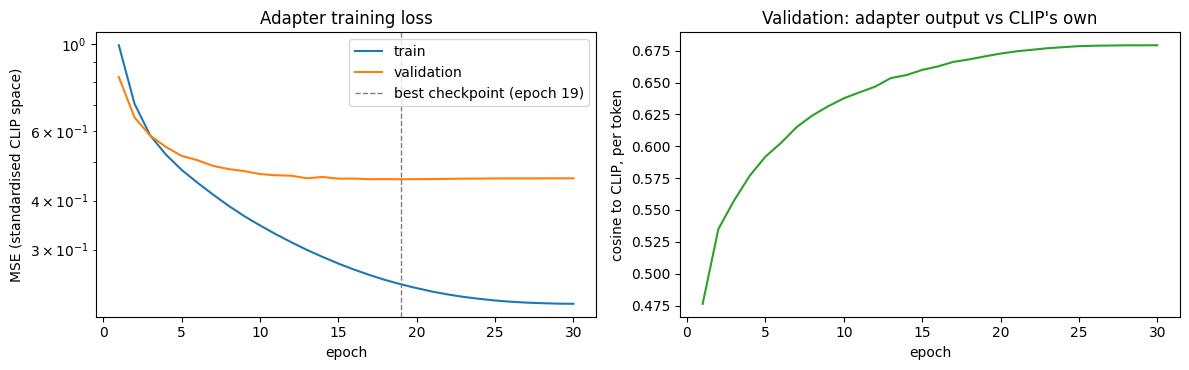

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(train_log["epoch"], train_log["train_loss"], label="train")
ax1.plot(train_log["epoch"], train_log["val_loss"], label="validation")
ax1.set_xlabel("epoch"); ax1.set_ylabel("MSE (standardised CLIP space)"); ax1.set_yscale("log")
ax1.set_title("Adapter training loss"); ax1.legend()
ax1.axvline(best["epoch"], color="grey", linestyle="--", linewidth=1, label=f"best checkpoint (epoch {best['epoch']})")
ax1.legend()
ax2.plot(train_log["epoch"], train_log["val_token_cosine"], color="tab:green")
ax2.set_xlabel("epoch"); ax2.set_ylabel("cosine to CLIP, per token")
ax2.set_title("Validation: adapter output vs CLIP's own")
plt.tight_layout()
plt.savefig(GRIDS_DIR / "adapter_training.png", dpi=110, bbox_inches="tight")
plt.show()

### 10b. Generating with BERT + adapter

Same prompts, latents and settings as the baseline; only the text encoder changes.

[     bert] bert_adapter                 CLIP 22.10 | vs baseline -4.93 | real-sim 0.670 |   7.54 s/img


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
encoder,,,,,,,
clip,27.026,0.000,0.000,0.754,6.398,10,0
bert_raw,9.099,-17.927,1.221,0.492,7.506,10,0
bert+adapter,22.095,-4.931,1.938,0.670,7.544,10,0


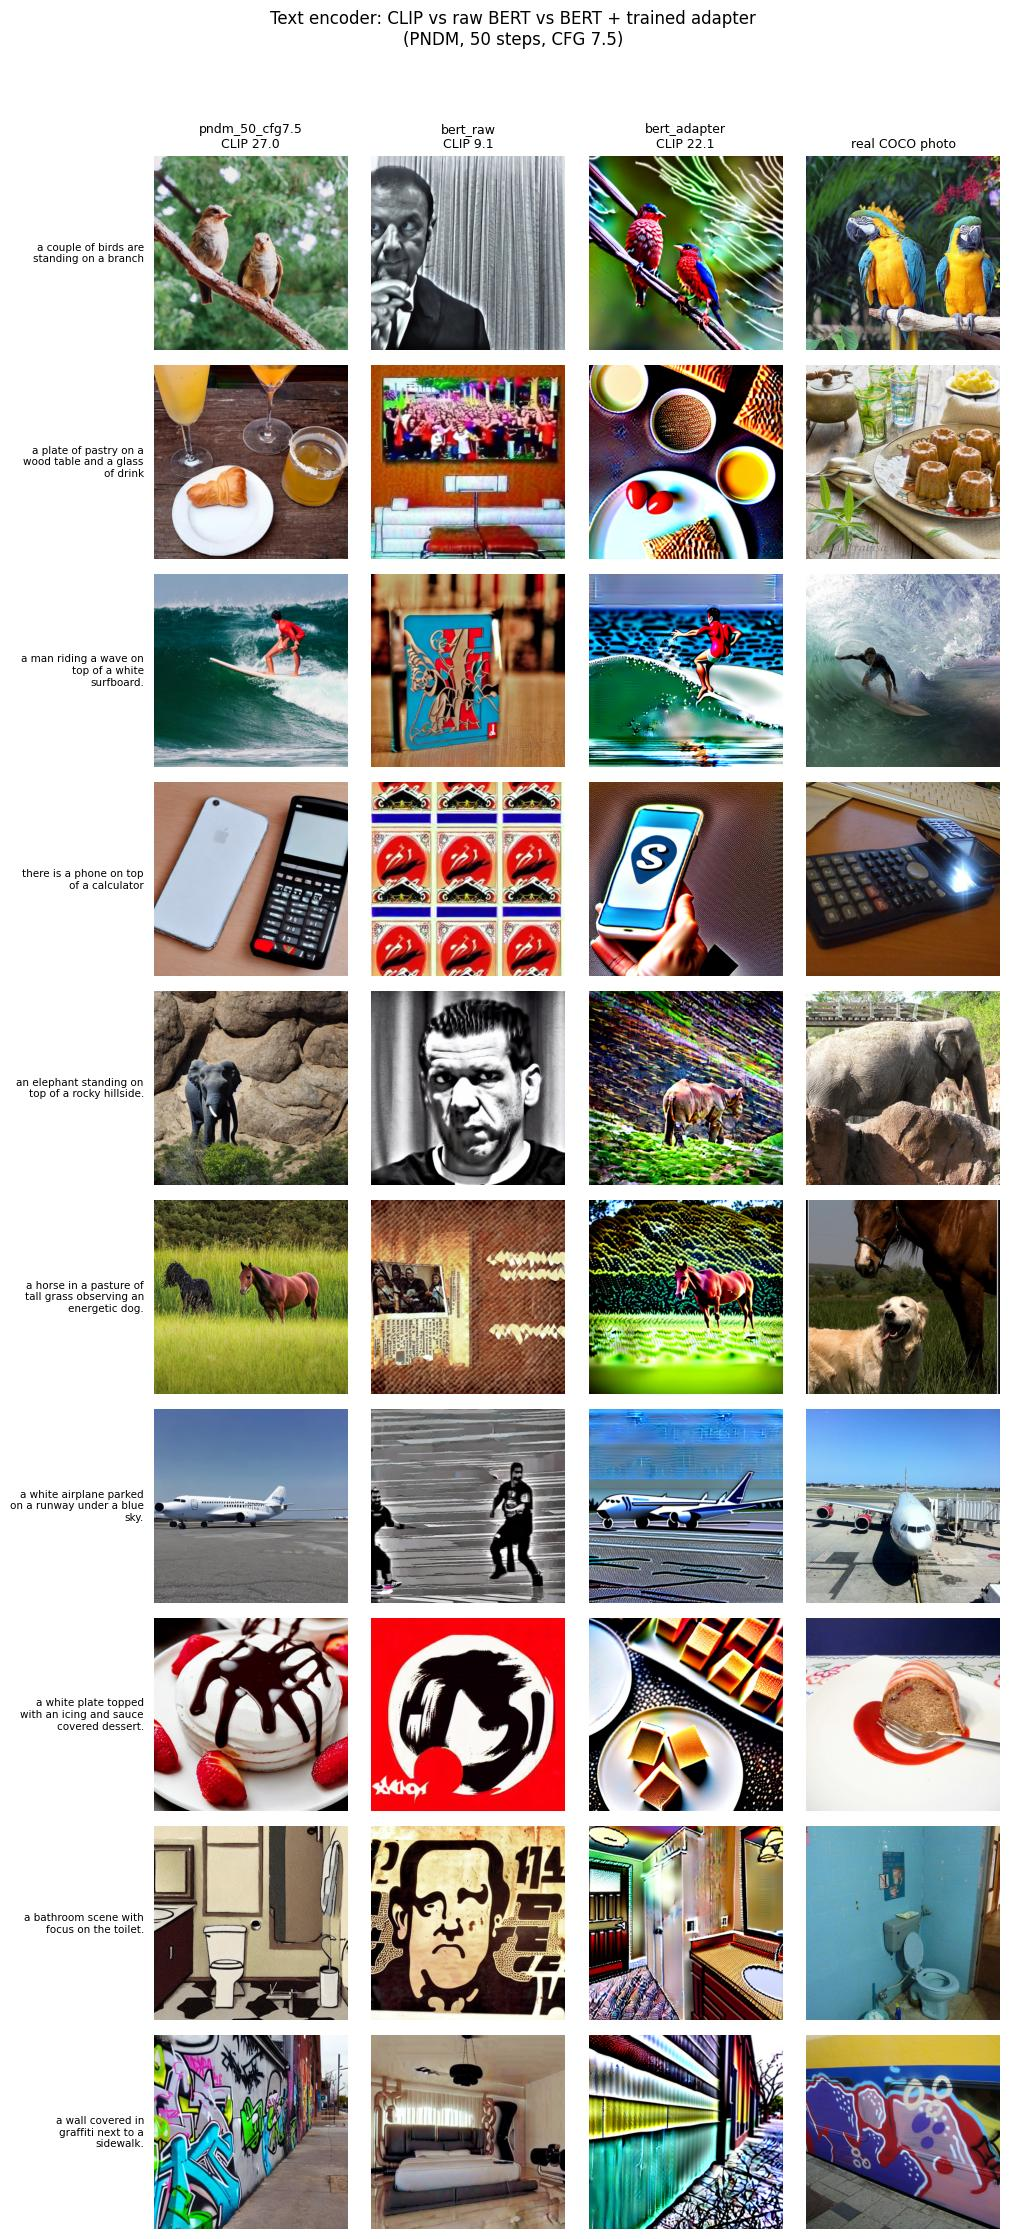

In [21]:
@torch.no_grad()
def adapter_encode(texts):
    adapter.eval()
    states, mask = bert_encode(texts)
    with torch.autocast("cuda", dtype=torch.float16):
        z = adapter(states, mask)
    return to_clip_space(z).to(DTYPE)


ad_cond, ad_uncond = adapter_encode(MAIN["prompts"]), adapter_encode([""])
run_config("bert", "bert_adapter", BASE["sampler"], BASE["steps"], BASE["cfg"],
           cond=ad_cond, uncond=ad_uncond, encoder="bert+adapter")
save_log()

encoder_table = paired_table(pd.DataFrame([r for r in LOG if (r["experiment"], r["config"]) in
                                           [("baseline", "pndm_50_cfg7.5"), ("bert", "bert_raw"), ("bert", "bert_adapter")]]),
                             ["encoder"])
encoder_table.to_csv(TABLES_DIR / "encoders.csv")
display(encoder_table)
show_grid([("baseline", "pndm_50_cfg7.5"), ("bert", "bert_raw"), ("bert", "bert_adapter")],
          "Text encoder: CLIP vs raw BERT vs BERT + trained adapter (PNDM, 50 steps, CFG 7.5)", "encoders")

## 11. Tuned settings on held-out prompts

The sweeps above each picked a best value on the main prompt set. Picking and judging on the same 10
prompts flatters the winner, so here the winners are combined into one **tuned** configuration and
compared with the baseline on the 10 **held-out** prompts, which none of the choices saw. A
**fast** configuration is added too: the fewest DPM-Solver++ steps whose score stayed within 0.5 of
the best step count.

tuned: {'sampler': 'euler_a', 'steps': 30, 'cfg': 7.5, 'scheduler_kwargs': {'timestep_spacing': 'trailing'}}
fast : {'sampler': 'dpmpp_2m', 'steps': 10, 'cfg': 7.5, 'scheduler_kwargs': {'timestep_spacing': 'trailing'}}
[  heldout] baseline                     CLIP 26.25 | real-sim 0.705 |   7.52 s/img
[  heldout] tuned                        CLIP 26.12 | vs baseline -0.13 | real-sim 0.706 |   4.49 s/img
[  heldout] fast                         CLIP 25.65 | vs baseline -0.30 | real-sim 0.694 |   1.65 s/img | 1 blocked by safety filter


,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
config,,,,,,,
baseline,26.253,0.000,0.000,0.705,7.518,10,0
tuned,26.120,-0.133,0.591,0.706,4.488,10,0
fast,25.650,-0.301,0.624,0.694,1.650,9,1


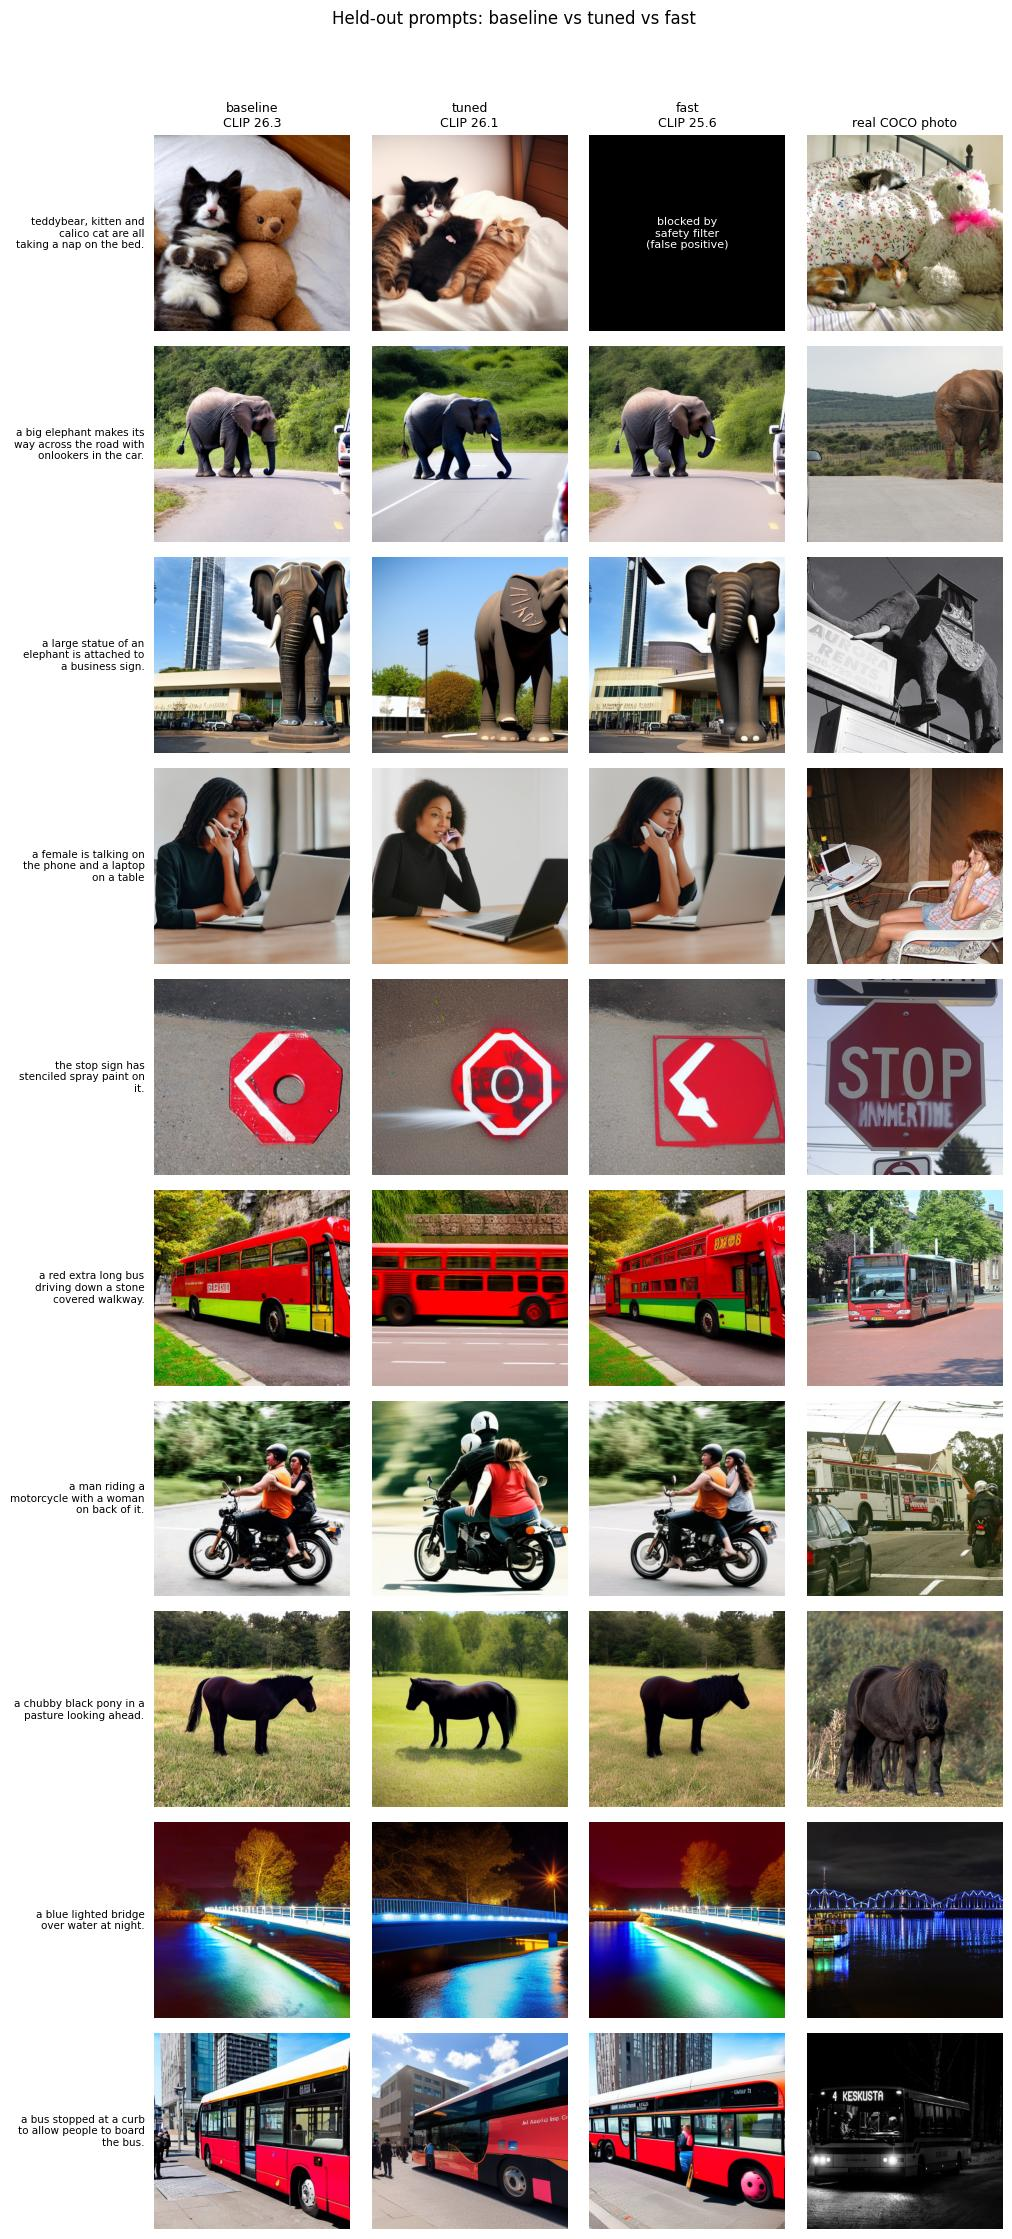

In [22]:
plain_cfg = cfg_table.loc[[f"cfg_{w:g}" for w in CFG_VALUES]]
best_cfg = CFG_VALUES[int(np.argmax(plain_cfg["clip_score"].to_numpy()))]
best_sampler = sampler_table["clip_score"].idxmax()
best_spacing = spacing_table["clip_score"].idxmax()
step_scores = steps_table.loc[[f"{n}_steps" for n in STEP_COUNTS], "clip_score"].to_numpy()
fast_steps = min(n for n, s in zip(STEP_COUNTS, step_scores) if s >= step_scores.max() - 0.5)

TUNED = dict(sampler=best_sampler, steps=SAMPLER_STEPS, cfg=best_cfg, scheduler_kwargs={"timestep_spacing": best_spacing})
FAST = dict(sampler=STEPS_SAMPLER, steps=fast_steps, cfg=best_cfg, scheduler_kwargs={"timestep_spacing": best_spacing})
print(f"tuned: {TUNED}")
print(f"fast : {FAST}")

run_config("heldout", "baseline", BASE["sampler"], BASE["steps"], BASE["cfg"], ps=HELDOUT)
run_config("heldout", "tuned", **TUNED, ps=HELDOUT)
run_config("heldout", "fast", **FAST, ps=HELDOUT)
save_log()
heldout_table = summarize("heldout")
display(heldout_table)
show_grid([("heldout", "baseline"), ("heldout", "tuned"), ("heldout", "fast")],
          "Held-out prompts: baseline vs tuned vs fast", "heldout")

## 12. Results

### Every configuration

One row per configuration on the main prompt set, ranked by CLIP score. `vs_baseline` is the mean
prompt-by-prompt difference from the baseline and `vs_baseline_se` its standard error. Differences
inside about two standard errors are noise at this sample size.

In [23]:
save_log()
log = pd.DataFrame(LOG)
main_rows = log[(log["prompt_set"] == "main") & (log["experiment"] != "ddpm")]  # DDPM ran on 2 prompts only
results = paired_table(main_rows, ["experiment", "config"]).sort_values("clip_score", ascending=False)
results.to_csv(TABLES_DIR / "all_configs.csv")
display(results)

,,clip_score,vs_baseline,vs_baseline_se,real_similarity,seconds_per_image,n_scored,n_safety_blocked
experiment,config,,,,,,,
sampler,euler_a,27.113,0.087,1.393,0.769,4.493,10,0
spacing,trailing,27.094,0.068,0.445,0.759,4.517,10,0
baseline,pndm_50_cfg7.5,27.026,0.000,0.000,0.754,6.398,10,0
cfg,cfg_7.5,27.026,0.000,0.000,0.754,7.532,10,0
steps,10_steps,26.967,-0.059,1.044,0.756,1.653,10,0
sampler,euler,26.774,-0.252,0.526,0.750,4.499,10,0
steps,50_steps,26.507,-0.519,0.781,0.735,7.390,10,0
cfg,cfg_5,26.497,-0.529,0.513,0.746,7.290,10,0
steps,30_steps,26.457,-0.569,0.560,0.739,4.508,10,0


### First set of generated images

The report's early samples: the 10 held-out prompts under the baseline and the tuned settings, with
the real COCO photo for each caption.

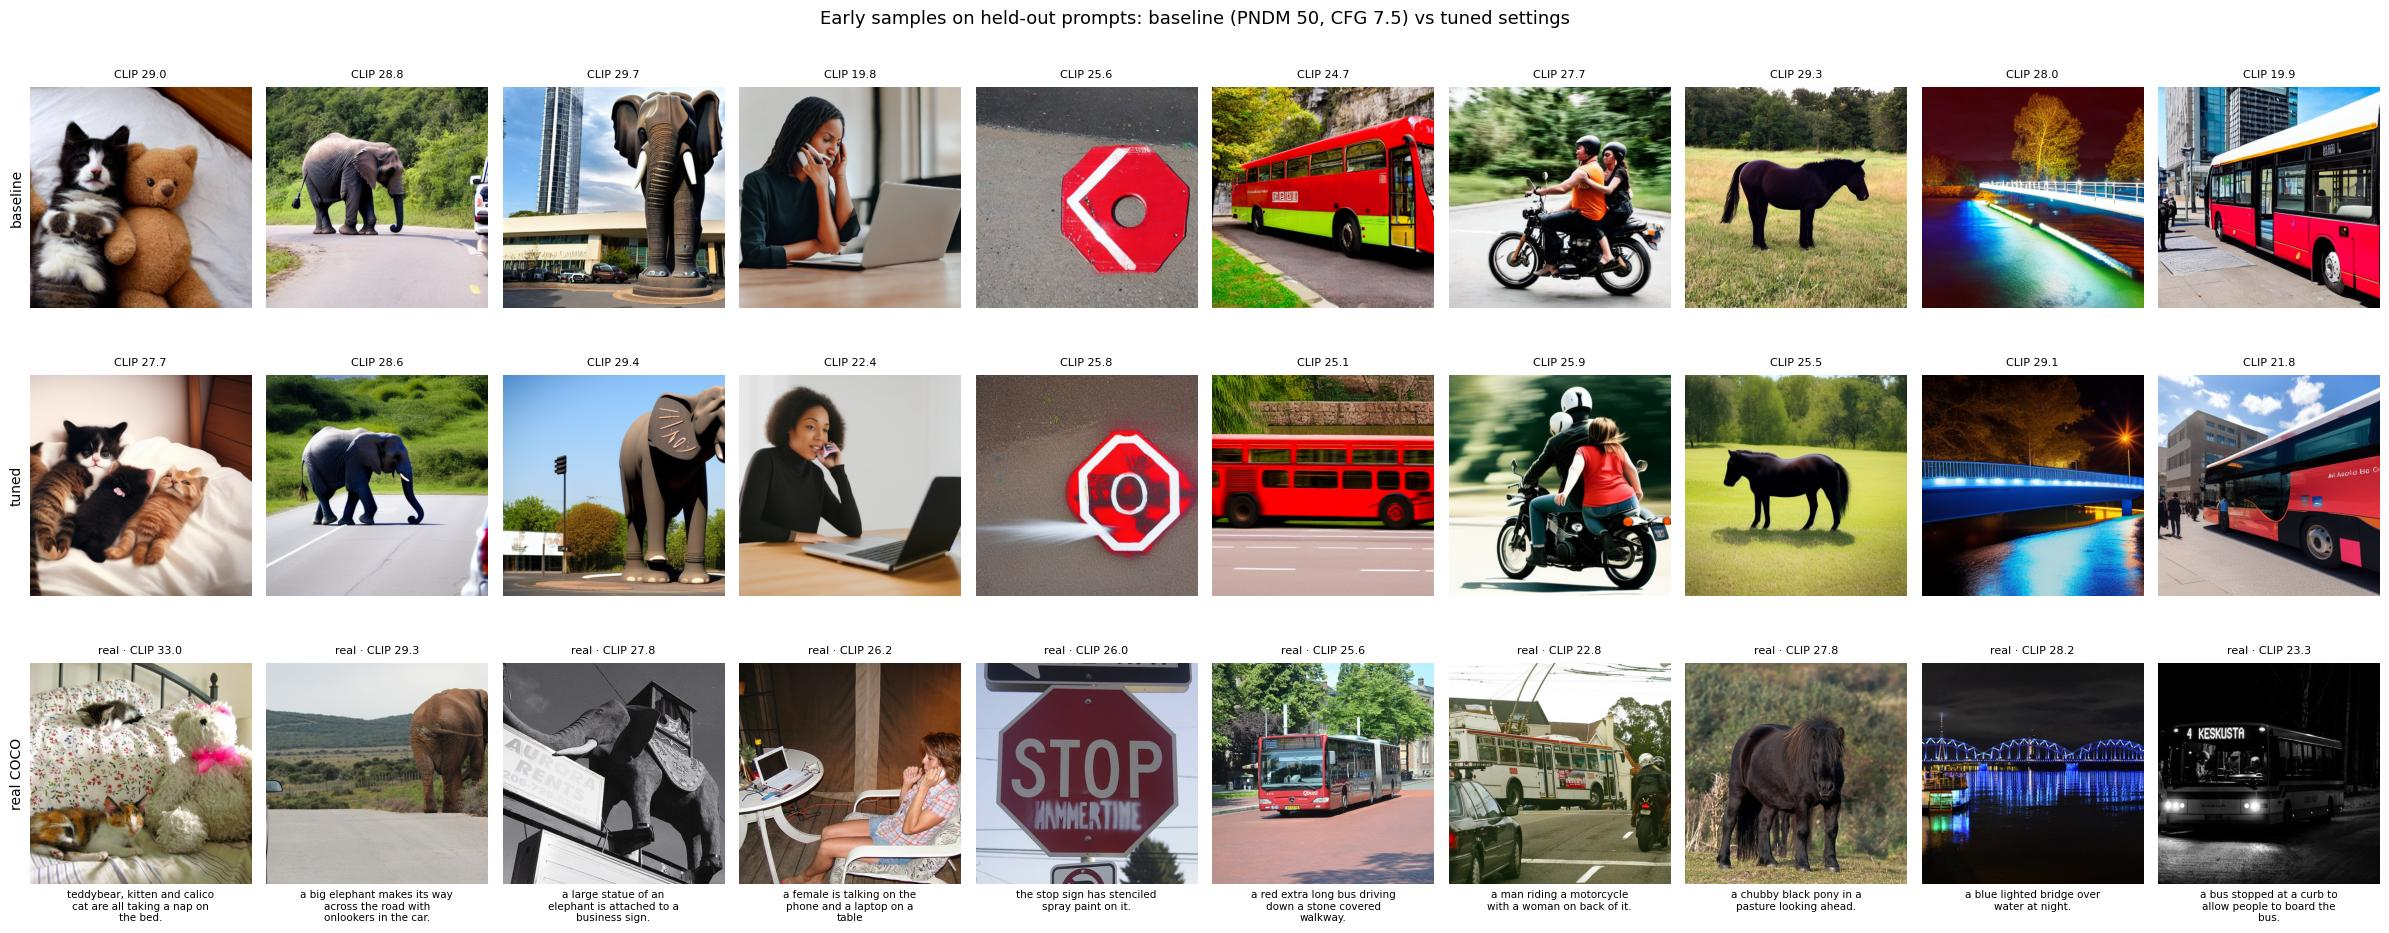

,prompt,baseline_clip,tuned_clip,real_photo_clip
0,"teddybear, kitten and calico cat are all takin...",28.97,27.69,32.98
1,a big elephant makes its way across the road w...,28.78,28.56,29.28
2,a large statue of an elephant is attached to a...,29.66,29.43,27.84
3,a female is talking on the phone and a laptop ...,19.83,22.43,26.16
4,the stop sign has stenciled spray paint on it.,25.59,25.83,26.02
5,a red extra long bus driving down a stone cove...,24.70,25.06,25.62
6,a man riding a motorcycle with a woman on back...,27.73,25.85,22.79
7,a chubby black pony in a pasture looking ahead.,29.34,25.49,27.81
8,a blue lighted bridge over water at night.,27.98,29.09,28.16
9,a bus stopped at a curb to allow people to boa...,19.95,21.77,23.32


In [24]:
ps = HELDOUT
rows_spec = [("heldout", "baseline"), ("heldout", "tuned")]
n = len(ps["prompts"])
fig, axes = plt.subplots(len(rows_spec) + 1, n, figsize=(2.4 * n, 2.75 * (len(rows_spec) + 1) + 1.4), squeeze=False)
for r, key in enumerate(rows_spec):
    rows = [x for x in LOG if (x["experiment"], x["config"]) == key]
    for c in range(n):
        axes[r, c].imshow(RUNS[key]["images"][c])
        axes[r, c].set_title("blocked by safety filter" if rows[c]["nsfw_flagged"] else f"CLIP {rows[c]['clip_score']:.1f}",
                             fontsize=8)
    axes[r, 0].set_ylabel(key[1], fontsize=10)
for c in range(n):
    axes[-1, c].imshow(ps["real_images"][c])
    axes[-1, c].set_title(f"real · CLIP {ps['real_clip'][c]:.1f}", fontsize=8)
    axes[-1, c].set_xlabel(textwrap.fill(ps["prompts"][c], 28), fontsize=7.5)
axes[-1, 0].set_ylabel("real COCO", fontsize=10)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle("Early samples on held-out prompts: baseline (PNDM 50, CFG 7.5) vs tuned settings", fontsize=13)
plt.tight_layout()
plt.savefig(GRIDS_DIR / "early_samples.png", dpi=120, bbox_inches="tight")
plt.show()

samples = pd.DataFrame({
    "prompt": ps["prompts"],
    "baseline_clip": [x["clip_score"] for x in LOG if (x["experiment"], x["config"]) == ("heldout", "baseline")],
    "tuned_clip": [x["clip_score"] for x in LOG if (x["experiment"], x["config"]) == ("heldout", "tuned")],
    "real_photo_clip": [round(s, 2) for s in ps["real_clip"]],
})
samples.to_csv(TABLES_DIR / "early_samples.csv", index=False)
display(samples)

## 13. Generation log

`outputs/milestone2/generation_log.csv` holds one row per generated image with every setting, its
timing and its scores. `adapter_training_log.csv` holds the adapter's per-epoch training record.
Below: the run totals and the first rows of the generation log.

In [25]:
run_info = {
    "images generated": len(log),
    "configurations": log.groupby(["experiment", "config"]).ngroups,
    "total generation time (min)": round(log["seconds_per_image"].sum() / 60, 1),
    "adapter training time (min)": round(train_minutes, 1),
    "adapter parameters (M)": round(n_adapter / 1e6, 1),
    "peak GPU memory (GB)": round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "safety-checker flags": int(log["nsfw_flagged"].sum()),
    "integration: max embedding diff": f"{embed_diff:.1e}",
    "integration: mean pixel diff": f"{pixel_diff.mean():.5f}",
    "tuned configuration": json.dumps(TUNED),
    "fast configuration": json.dumps(FAST),
    "GPU": gpu.name,
    "torch / diffusers / transformers": f"{torch.__version__} / {diffusers.__version__} / {transformers.__version__}",
}
(OUT_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2))
display(pd.Series(run_info, name="value").to_frame())
display(log.head(10))

,value
images generated,304
configurations,32
total generation time (min),30.9
adapter training time (min),4.1
adapter parameters (M),24.9
peak GPU memory (GB),6.19
safety-checker flags,1
integration: max embedding diff,1.6e-02
integration: mean pixel diff,0.00743
tuned configuration,"{""sampler"": ""euler_a"", ""steps"": 30, ""cfg"": 7.5..."


,experiment,config,prompt_set,encoder,sampler,steps,cfg,guidance_rescale,beta_schedule,timestep_spacing,karras_sigmas,prompt_id,prompt,latent_seed,noise_seed,seconds_per_image,clip_score,real_similarity,nsfw_flagged,file
0,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,0,a couple of birds are standing on a branch,42,43,6.311,25.55,0.8111,False,images/baseline/pndm_50_cfg7.5/main_p00.png
1,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,1,a plate of pastry on a wood table and a glass ...,42,44,6.311,26.32,0.6297,False,images/baseline/pndm_50_cfg7.5/main_p01.png
2,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,2,a man riding a wave on top of a white surfboard.,42,45,6.311,23.46,0.8733,False,images/baseline/pndm_50_cfg7.5/main_p02.png
3,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,3,there is a phone on top of a calculator,42,46,6.311,28.60,0.7922,False,images/baseline/pndm_50_cfg7.5/main_p03.png
4,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,4,an elephant standing on top of a rocky hillside.,42,47,6.311,28.43,0.7588,False,images/baseline/pndm_50_cfg7.5/main_p04.png
5,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,5,a horse in a pasture of tall grass observing a...,42,48,6.485,32.84,0.8368,False,images/baseline/pndm_50_cfg7.5/main_p05.png
6,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,6,a white airplane parked on a runway under a bl...,42,49,6.485,23.94,0.6886,False,images/baseline/pndm_50_cfg7.5/main_p06.png
7,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,7,a white plate topped with an icing and sauce c...,42,50,6.485,26.35,0.7055,False,images/baseline/pndm_50_cfg7.5/main_p07.png
8,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,8,a bathroom scene with focus on the toilet.,42,51,6.485,29.03,0.6925,False,images/baseline/pndm_50_cfg7.5/main_p08.png
9,baseline,pndm_50_cfg7.5,main,clip,pndm,50,7.5,0.0,scaled_linear,leading,False,9,a wall covered in graffiti next to a sidewalk.,42,52,6.485,25.74,0.7555,False,images/baseline/pndm_50_cfg7.5/main_p09.png


## 14. Observations

**Integration works.** Our own CLIP text encoder drives the UNet through `prompt_embeds`. Its output
matches Stable Diffusion's built-in encoding to within 0.016 (float16 rounding, on values up to 33),
and the images from the two paths differ by 0.7% per pixel on average.

**Baseline.** SD v1.5's defaults (PNDM, 50 steps, CFG 7.5) score 27.0 on the main prompts, above
the real COCO photos for the same captions (23.6). That is expected: the generator draws exactly what
the caption says, while the photo came first and the caption describes it loosely. CLIP score
measures prompt adherence, not realism.

**Guidance has a clear sweet spot at 7.5.** Scores form an inverted U. At `w = 1` (no guidance)
scenes fall apart (−4.3 ± 1.1 against the baseline); at 3 they are recognisable but loose (−1.1).
Above 7.5 the score falls again (−0.6 at 10, −0.9 at 15) and colours oversaturate.
`guidance_rescale = 0.7` at 15 tempers the saturation and recovers a little (+0.2). Similarity to
the real photo peaks at the same scale.

**Noise schedule.**
* **Timestep spacing is the biggest single lever.** On the same DDIM sampler, `trailing` scores
  27.1 against 25.8 for SD's default `leading` (+1.27 ± 0.60 prompt by prompt). `leading` never visits the pure-noise end (its first
  step is t = 958, not 999), so the sampler starts from a latent noisier than the timestep it
  is told.
* **Samplers at an equal 30 steps:** Euler ancestral (27.1) and Euler (26.8) lead. PNDM and DDIM
  trail (−1.4 ± 0.6 and −1.2 ± 0.7). PNDM needs the 50 steps it defaults to.
* **Beta schedule:** the UNet was trained on `scaled_linear`. `linear` and `squaredcos_cap_v2`
  change the look (higher contrast and saturation; softer, flatter images) more than the score,
  and the score differences sit inside the noise (+0.55 ± 0.77 and +0.28 ± 0.61).
* **Steps:** DPM-Solver++ at 10 steps (26.97) matches its own 50-step result (26.51) at 4.5× the
  speed (1.7 s against 7.4 s per image). Karras sigma spacing did not help at 10 steps (−0.9).
* **DDPM** at 1,000 steps took 147 s per image against 3.1 s for DPM-Solver++ at 20, about 47×
  slower, for no better score on the 2 prompts tested.

**BERT needs an adapter.** BERT's 768-d states plugged straight into the UNet score 9.1
(−17.9 ± 1.2): the images ignore the prompt entirely (faces, posters, patterns), because the UNet
only understands CLIP's embedding space. The trained adapter (24.9M parameters, 4 minutes, nothing
else trained) raises this to 22.1, closing about 73% of the gap to CLIP. Its images show the right
subjects (birds on a branch, a surfer, an airplane on a runway, a bathroom) but with noisy,
oversaturated textures, the cost of embeddings that reach only 0.68 cosine to CLIP's own. The
training log shows validation loss flattening by epoch 15–19 while training loss keeps falling, so
the adapter is limited by its 5,700 training captions; COCO's full training split (about 590,000
captions) is the obvious next step.

**On unseen prompts, tuning buys speed, not quality.** The winners of each sweep, combined
(Euler ancestral, `trailing` spacing, 30 steps, CFG 7.5), score −0.13 ± 0.59 against the baseline on
the 10 held-out prompts: no measurable difference. The small gains they showed on the main set did
not transfer. They are, however, 40% faster (4.5 s against 7.5 s per image). The fast configuration
(DPM-Solver++, 10 steps) is −0.30 ± 0.62 at 4.6× the speed, and its images keep the baseline's
compositions almost exactly: deterministic solvers started from the same latent converge on the same
picture. SD v1.5's defaults are already close to optimal for prompt adherence.

**Caveats.** With 10 prompts per set, differences under about 1 CLIP point are within two standard
errors. CLIP score rewards adherence, not image quality. The safety checker blocked one harmless
image (a false positive), which is excluded from the averages and labelled in the grid.

**Next (Milestone 3):** FID and Inception Score on a larger generated set, to measure realism
alongside adherence. Possibly also LoRA fine-tuning on the COCO subset, and training the BERT adapter
on more captions.